# **Autoencoders y Autoencoders Variacionales (VAE)**



### **Aplicaciones de los autoencoders (AE y VAE)**


| **Autoencoders (AE)** | **Autoencoders variacionales (VAE)** |
|:---|:---|
| **Reducción dimensional:** códigos compactos y comparación con PCA. | **Generación de imágenes:** muestreo del prior y generación de dígitos MNIST. |
| **Reconstrucción:** entrada → espacio latente → reconstrucción (*Fashion-MNIST*). | **Interpolación latente:** transiciones continuas entre imágenes. |
| **Eliminación de ruido:** recuperación de imágenes mediante DAE (*denoising*). | **Generación condicionada:** imágenes por clase mediante CVAE. |
| **Representaciones robustas:** regularización mediante AE contractivos. | **Modelado probabilístico:** ELBO, KL, reparametrización, IWAE y β-VAE (tasa–distorsión). |
| **Detección de anomalías:** análisis del error de reconstrucción. | **Diagnóstico generativo:** colapso posterior, dimensiones latentes activas y anomalías. |
| **Visualización:** agrupamientos y limitaciones del espacio latente 2D. | **Enfoque:** aprendizaje de distribuciones latentes y generación de nuevas observaciones. |



### **3. Representación**

Un autoencoder determinista aprende un **codificador** $g_\phi$ y un **decodificador** $f_\theta$:

$$
\boxed{x\in\mathbb R^l\ \xrightarrow{\;g_\phi\;}\ z\in\mathbb R^m\ \xrightarrow{\;f_\theta\;}\ \widehat x\in\mathbb R^l.}
$$

Para el AE se minimiza una pérdida de reconstrucción $\mathcal L_{\mathrm{rec}}(x,\widehat x)$. El **VAE** aprende una distribución aproximada $q_\phi(z\mid x)$ y, en la formulación habitual, minimiza

$$
\boxed{\mathcal J_{\mathrm{VAE}}=\underbrace{-\mathbb E_{q_\phi(z\mid x)}\log p_\theta(x\mid z)}_{\mathrm{reconstrucción}}+\underbrace{D_{\mathrm{KL}}\!\left(q_\phi(z\mid x)\|p(z)\right)}_{\mathrm{regularización}}.}
$$


### **Figura 1 · Panorama conceptual de Autoencoders y VAE**

```{figure} imgs/esquema_autoencoder_vae.png
:width: 95%
:align: center
:name: fig-arquitectura-vae

**Figura. Arquitectura del Autoencoder Variacional (VAE).** Codificador probabilístico, espacio latente, truco de reparametrización y decodificador.
```

*Esquema de entrada, codificación, espacio latente, reconstrucción y aplicaciones. La figura sintetiza los conceptos; las expresiones exactas se desarrollan matemáticamente en las secciones siguientes.*

**Nota de precisión:** la entropía cruzada binaria **completa** es

$$
\mathcal L_{\mathrm{BCE}}=-\sum_i\left[x_i\log\widehat x_i+(1-x_i)\log(1-\widehat x_i)\right].
$$

La expresión abreviada representada en la infografía es **solo uno de sus términos**, no la pérdida BCE general.


In [1]:
# ==== Configuración global (ejecutar primero) ====
import os, math, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
print("TensorFlow:", tf.__version__)
print("GPU disponible:", bool(tf.config.list_physical_devices("GPU")))

I0000 00:00:1795147332.940810  346919 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795147333.084160  346919 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795147334.989347  346919 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU disponible: False


W0000 00:00:1795147337.754438  346919 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...



# **PARTE I  Autoencoders**

## I.1 **Definición y entrenamiento**

In [ ]:
# Esquema autocontenido de un autoencoder (no requiere archivos de imágenes externos)
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(10, 3.0))
ax.set_xlim(0, 10); ax.set_ylim(0, 3); ax.axis('off')
blocks = [(0.4, 'Entrada', r'$\mathbf{x}\in\mathbb{R}^{\ell}$', '#dbeafe'),
          (2.8, 'Codificador', r'$g_{\phi}$', '#c7d2fe'),
          (5.2, 'Espacio latente', r'$\mathbf{z}\in\mathbb{R}^{m}$', '#ddd6fe'),
          (7.6, 'Decodificador', r'$f_{\theta}$', '#c7d2fe')]
for x0, name, formula, color in blocks:
    ax.add_patch(FancyBboxPatch((x0, 0.92), 2.0, 1.17, boxstyle='round,pad=0.15',
                                fc=color, ec='#475569', lw=1.2))
    ax.text(x0+1, 1.70, name, ha='center', va='center', weight='bold', fontsize=10)
    ax.text(x0+1, 1.23, formula, ha='center', va='center', fontsize=11)
for start in [2.45, 4.85, 7.25]:
    ax.add_patch(FancyArrowPatch((start,1.5),(start+0.29,1.5),arrowstyle='-|>',
                                  mutation_scale=18,color='#334155',lw=1.7))
ax.text(8.6, 0.49, r'Salida: $\hat{\mathbf{x}}$', ha='center', fontsize=11)
ax.text(5, 2.64, r'Objetivo: minimizar $\mathcal{L}(\mathbf{x},\hat{\mathbf{x}})$',
        ha='center', fontsize=12, weight='bold')
plt.tight_layout(); plt.show()

### **Codificador: de los datos al espacio latente**

El **codificador** $g_\phi$ transforma cada observación $x\in\mathbb R^l$ en una representación $z\in\mathbb R^m$. Cuando $m<l$, la representación tiene **menor dimensión** que la entrada:

$$
\boxed{g_\phi:\mathbb R^l\to\mathbb R^m,\qquad z=g_\phi(x).}
$$

**Para una capa de codificación**, cada componente se calcula como

$$
z_i=\phi_e\left(\boldsymbol\theta_i^Tx+b_i\right),\qquad i=1,\ldots,m.
$$

- **$\boldsymbol\theta_i$:** vector de pesos de la unidad $i$; **$b_i$:** sesgo.
- **$\phi_e$:** función de activación (por ejemplo, sigmoide, ReLU o identidad).
- **$z_i$:** coordenada aprendida del código latente; no tiene necesariamente una interpretación física predefinida.

**Idea central:** el codificador aprende qué información conservar para poder reconstruir la entrada con el decodificador.


### **Decodificador: del código a la reconstrucción**

El **decodificador** $f_\theta$ transforma el código $z$ en una reconstrucción $\widehat x$ con la misma dimensión que el dato original:

$$
\boxed{f_\theta:\mathbb R^m\to\mathbb R^l,\qquad \widehat x=f_\theta(z).}
$$

Para una capa de salida, la coordenada reconstruida $j$ puede expresarse como

$$
\widehat x_j=\phi_d\left({\boldsymbol\theta'_j}^Tz+b'_j\right),\qquad j=1,\ldots,l.
$$

- **$\boldsymbol\theta'_j$ y $b'_j$:** pesos y sesgo de la unidad de salida $j$.
- **$\phi_d$:** activación compatible con los datos; por ejemplo, identidad para una salida real o sigmoide para valores en $[0,1]$.
- **$\widehat x_j$:** valor reconstruido que se compara con $x_j$ durante el entrenamiento.


### **Parámetros del autoencoder**

El entrenamiento estima conjuntamente los parámetros del **codificador** y del **decodificador**:

$$
\boxed{\phi=(\Theta,b),\qquad \theta=(\Theta',b'),\quad
\Theta=[\boldsymbol\theta_1,\ldots,\boldsymbol\theta_m],\quad
\Theta'=[\boldsymbol\theta'_1,\ldots,\boldsymbol\theta'_l].}
$$

Los **pesos** y **sesgos** se actualizan mediante el algoritmo de optimización a partir de los gradientes de la pérdida de reconstrucción.


### **Aprendizaje y error de reconstrucción**

Para cada observación definimos el **residuo de reconstrucción** $e=x-\widehat x$. La red se entrena para minimizar una función de pérdida sobre el conjunto de datos:

$$
\boxed{\mathcal J(\phi,\theta)=\frac1N\sum_{n=1}^N\ell\!\left(x^{(n)},f_\theta(g_\phi(x^{(n)}))\right).}
$$

- **Pérdida cuadrática:** $\ell(x,\widehat x)=\|x-\widehat x\|_2^2$, apropiada para ciertas reconstrucciones continuas.
- **Entropía cruzada binaria:** se emplea al modelar observaciones con una verosimilitud Bernoulli, con salida en $(0,1)$.
- **Pesos atados:** en algunas arquitecturas se impone $\Theta'=\Theta^T$; **no** es un requisito general de los autoencoders.
- **Regularización:** restricciones sobre parámetros, códigos o sensibilidad pueden evitar soluciones triviales, en particular cuando $m\ge l$.

**Conexión con PCA:** bajo las hipótesis del **Teorema 1**, un AE **lineal** de rango $m<l$ y pérdida cuadrática aprende el subespacio principal de dimensión $m$; esto no implica que los pesos individuales sean únicos.



### **Formulación como problema de optimización**

**Definición 1 (Autoencoder).** Sea $\mathcal{X}\subseteq\mathbb{R}^{l}$ el espacio de datos y $m<l$ la dimensión del código latente. Un **autoencoder (AE)** consta de dos funciones:

- **Codificador:** $g_\phi:\mathbb{R}^{l}\to\mathbb{R}^{m}$, que transforma la entrada en una representación latente $\boldsymbol{z}=g_\phi(\boldsymbol{x})$.
- **Decodificador:** $f_\theta:\mathbb{R}^{m}\to\mathbb{R}^{l}$, que reconstruye la entrada mediante $\hat{\boldsymbol{x}}=f_\theta(\boldsymbol{z})$.

El entrenamiento consiste en **minimizar el error de reconstrucción**:

$$
\boxed{
\min_{\phi,\theta}\;\mathcal{J}(\phi,\theta)
=\frac{1}{N}\sum_{n=1}^{N}
\left\|\boldsymbol{x}^{(n)}
-f_\theta\big(g_\phi(\boldsymbol{x}^{(n)})\big)\right\|_2^2
}
$$

donde **$N$** es el número de observaciones, **$\phi,\theta$** son los parámetros entrenables y **$\|\cdot\|_2^2$** representa el error cuadrático de reconstrucción.

**Observación (cuello de botella).**
- Si **$m<l$**, el modelo comprime la información (*undercomplete*).
- Si **$m\geq l$**, puede aprender la identidad sin extraer representaciones útiles.
- La **regularización** permite introducir restricciones adicionales que favorezcan representaciones estructuradas.

**Interpretación probabilística.** Supongamos que el decodificador define una distribución gaussiana con varianza fija:

$$
p_\theta(\boldsymbol{x}\mid\boldsymbol{z})
=\mathcal{N}\left(
\boldsymbol{x};
f_\theta(\boldsymbol{z}),\sigma^2 I
\right).
$$

**¿Qué queremos demostrar?** Que minimizar el error cuadrático equivale a maximizar la log-verosimilitud gaussiana cuando $\sigma^2$ es constante.

**Demostración.** La densidad gaussiana multivariante es:

$$
p_\theta(\boldsymbol{x}\mid\boldsymbol{z})
=\frac{1}{(2\pi\sigma^2)^{l/2}}
\exp\left(
-\frac{\|\boldsymbol{x}-f_\theta(\boldsymbol{z})\|_2^2}
{2\sigma^2}
\right).
$$

**Paso 1.** Aplicamos el logaritmo natural:

$$
\log p_\theta(\boldsymbol{x}\mid\boldsymbol{z})
=-\frac{l}{2}\log(2\pi\sigma^2)
-\frac{\|\boldsymbol{x}-f_\theta(\boldsymbol{z})\|_2^2}
{2\sigma^2}.
$$

**Paso 2.** Multiplicamos por $-1$:

$$
-\log p_\theta(\boldsymbol{x}\mid\boldsymbol{z})
=\frac{1}{2\sigma^2}
\|\boldsymbol{x}-f_\theta(\boldsymbol{z})\|_2^2
+\frac{l}{2}\log(2\pi\sigma^2).
$$

**Paso 3.** Como $\sigma^2$ es fija, el último término es constante y el factor $1/(2\sigma^2)$ es positivo. Por tanto:

$$
\boxed{
\arg\min_{\phi,\theta}\mathcal{J}
=\arg\max_{\phi,\theta}
\sum_{n=1}^{N}
\log p_\theta\!\left(
\boldsymbol{x}^{(n)}
\mid g_\phi(\boldsymbol{x}^{(n)})
\right)
}
$$

Bajo el supuesto gaussiano de varianza fija, **minimizar el error cuadrático de reconstrucción es equivalente a maximizar la log-verosimilitud condicional**. 



## **I.2. Autoencoder lineal y PCA**

Recordemos el resultado clásico del **análisis de componentes principales (PCA)**. Sea $\boldsymbol{X}\in\mathbb{R}^{N\times l}$ una matriz de datos con filas centradas, cuya matriz de covarianza es:

$$
\Sigma=\frac{1}{N}\boldsymbol{X}^{T}\boldsymbol{X},
$$

con **autovalores** $\lambda_1\geq\lambda_2\geq\cdots\geq\lambda_l\geq0$ y **autovectores ortonormales** $\boldsymbol{v}_1,\ldots,\boldsymbol{v}_l$.

**Teorema (Eckart–Young–Mirsky / PCA).** Entre todas las **proyecciones ortogonales** $\boldsymbol{P}$ de rango $m<l$, el error cuadrático medio de reconstrucción se minimiza al proyectar los datos sobre los $m$ autovectores asociados con los mayores autovalores:

$$
\boxed{
\boldsymbol{P}^{*}=\boldsymbol{V}_m\boldsymbol{V}_m^{T},
\qquad
\boldsymbol{V}_m=[\boldsymbol{v}_1,\ldots,\boldsymbol{v}_m]
}
$$

El **error mínimo de reconstrucción** corresponde a la suma de los autovalores descartados [5]:

$$
\boxed{
\min_{\operatorname{rank}(\boldsymbol{P})=m}
\mathbb{E}\|\boldsymbol{x}-\boldsymbol{P}\boldsymbol{x}\|_2^2
=\sum_{i=m+1}^{l}\lambda_i
}
$$

**Interpretación:** PCA conserva las $m$ direcciones de **mayor varianza** y descarta las restantes, minimizando así la pérdida de información medida mediante el error cuadrático de reconstrucción.

**Pregunta central:** ¿Qué representación aprende un **autoencoder lineal** cuando se entrena minimizando el error cuadrático? ¿Coincide con el subespacio obtenido mediante PCA?


### **Teorema 1 · Autoencoder lineal y análisis de componentes principales**

**¿Qué queremos demostrar y por qué?** Que un **autoencoder lineal de cuello de botella** (sin sesgos y con pérdida cuadrática) encuentra el mismo **subespacio óptimo** que PCA. Esto explica qué aprende realmente una representación latente lineal y por qué sus coordenadas no tienen una orientación única.

**Hipótesis.** Los datos están centrados, $\Sigma=\mathbb E[xx^T]\succ0$, con autovalores distintos $\lambda_1>\cdots>\lambda_l>0$ y autovectores ortonormales $v_i$. Sean $W_1\in\mathbb R^{m\times l}$, $W_2\in\mathbb R^{l\times m}$, $m<l$ y $\widehat x=W_2W_1x$. Minimizamos $J=\mathbb E\|x-W_2W_1x\|^2$.

- **Puntos críticos no degenerados:** si $W_1$ y $W_2$ tienen rango $m$, su producto $W_2W_1$ es el proyector ortogonal sobre un subespacio generado por $m$ autovectores de $\Sigma$.
- **Óptimo global:** el proyector sobre los primeros $m$ autovectores minimiza $J$ y produce $J_{\min}=\sum_{i=m+1}^{l}\lambda_i$.
- **Otros puntos críticos:** las elecciones no principales de rango completo son puntos silla; la formulación sin restricciones también admite puntos críticos degenerados, que **no** deben omitirse.
- **No identificabilidad:** si $B\in GL_m$, $W_1\mapsto BW_1$ y $W_2\mapsto W_2B^{-1}$ dejan intactas las reconstrucciones.

**Referencia guía:** Baldi y Hornik (1989, [1]); para la interpretación mediante PCA y SVD, Bourlard y Kamp (1988, [2]).


#### **Demostración detallada · Teorema 1 (Baldi–Hornik)**

**Objetivo.** Caracterizar los puntos estacionarios no degenerados, encontrar el error mínimo y probar que las selecciones incorrectas de autovectores no son mínimos locales.

**Paso 1. Reescribir la pérdida.** Sea $A=W_2W_1$, con $\operatorname{rango}(A)\le m$. Puesto que $\mathbb E[x]=0$ y $\Sigma=\mathbb E[xx^T]$,

$$
\begin{aligned}
J&=\mathbb E[(x-Ax)^T(x-Ax)]\\
 &=\operatorname{tr}[(I-A)\Sigma(I-A)^T]\\
 &=\operatorname{tr}(\Sigma)-2\operatorname{tr}(A\Sigma)+\operatorname{tr}(A\Sigma A^T).
\end{aligned}
$$

**Paso 2. Derivar respecto de ambas matrices.** Mediante $dJ=2\operatorname{tr}[(A-I)\Sigma\,dA^T]$ y $dA=dW_2W_1+W_2dW_1$,

$$
\boxed{\nabla_{W_2}J=2(W_2W_1-I)\Sigma W_1^T},\qquad
\boxed{\nabla_{W_1}J=2W_2^T(W_2W_1-I)\Sigma}.
$$

**Paso 3. Obtener la proyección ortogonal.** Supongamos $\operatorname{rango}(W_1)=m$ y estacionariedad. De $\nabla_{W_2}J=0$,

$$
W_2(W_1\Sigma W_1^T)=\Sigma W_1^T
\quad\Longrightarrow\quad
W_2=\Sigma W_1^T(W_1\Sigma W_1^T)^{-1}.
$$

Así $W_2$ tiene rango $m$. Usamos ahora $\nabla_{W_1}J=0$ y la invertibilidad de $\Sigma$:

$$
W_2^T(W_2W_1-I)=0
\quad\Longrightarrow\quad
\boxed{W_1=(W_2^TW_2)^{-1}W_2^T}.
$$

Por consiguiente,

$$
\boxed{A=W_2(W_2^TW_2)^{-1}W_2^T}.
$$

Esta expresión es **simétrica** ($A^T=A$) e **idempotente**:

$$
A^2=W_2(W_2^TW_2)^{-1}\underbrace{W_2^TW_2}_{\text{identidad intermedia}}(W_2^TW_2)^{-1}W_2^T=A.
$$

Por tanto, $A$ es el **proyector ortogonal** de rango $m$ sobre $\operatorname{Im}(W_2)$. En particular, este paso justifica la afirmación que antes quedaba sin demostrar.

**Paso 4. Demostrar invariancia respecto de la covarianza.** Sustituimos $W_1$ en $\nabla_{W_2}J=0$:

$$
(A-I)\Sigma W_2(W_2^TW_2)^{-1}=0
\quad\Longrightarrow\quad (I-A)\Sigma W_2=0.
$$

Para cualquier $u\in\operatorname{Im}(W_2)$ se cumple $Au=u$; la igualdad anterior implica $A\Sigma u=\Sigma u$, es decir, $\Sigma u\in\operatorname{Im}(W_2)$. El subespacio aprendido es **invariante bajo $\Sigma$**. Puesto que $\Sigma$ es simétrica y tiene espectro simple, los subespacios invariantes de dimensión $m$ están generados por elecciones de $m$ autovectores $v_i$. Así, para algún conjunto $\mathcal I$ de tamaño $m$,

$$
\boxed{A=P_{\mathcal I}=\sum_{i\in\mathcal I}v_iv_i^T}.
$$

**Paso 5. Calcular el mínimo global.** Como $P_{\mathcal I}^T=P_{\mathcal I}=P_{\mathcal I}^2$,

$$
J(P_{\mathcal I})=\operatorname{tr}[(I-P_{\mathcal I})\Sigma]
=\sum_{i\notin\mathcal I}\lambda_i.
$$

Este valor se minimiza conservando los **$m$ autovalores más grandes**. Más generalmente, el teorema de Eckart–Young garantiza que ninguna matriz de rango menor o igual a $m$ puede mejorar ese valor, porque $J=\|(I-A)\Sigma^{1/2}\|_F^2$. Por tanto,

$$
\boxed{J_{\min}=\sum_{i=m+1}^{l}\lambda_i,\qquad A_*=V_mV_m^T}.
$$

**Paso 6. Probar que una selección incorrecta es silla.** Si $\mathcal I$ no contiene los $m$ mayores autovalores, existen $i\in\mathcal I$ y $j\notin\mathcal I$ tales que $\lambda_j>\lambda_i$. Sustituimos $v_i$ por $u(\alpha)=\cos\alpha\,v_i+\sin\alpha\,v_j$, conservando las demás direcciones. El nuevo proyector $P(\alpha)$ es factorizable como $W_2(\alpha)W_1(\alpha)$ y satisface

$$
\begin{aligned}
J(P(\alpha))-J(P(0))
&=\lambda_i-\big(\lambda_i\cos^2\alpha+\lambda_j\sin^2\alpha\big)\\
&=-(\lambda_j-\lambda_i)\sin^2\alpha<0\quad(\alpha\ne0\text{ pequeño}).
\end{aligned}
$$

Así, existe una dirección de descenso alrededor del punto estacionario: **no es un mínimo local**. Incluso, la segunda derivada es $-2(\lambda_j-\lambda_i)<0$. **C.Q.D.**

> **Alcance del resultado.** La caracterización anterior presupone rango $m$. Con factores degenerados pueden existir otros puntos estacionarios; no es correcto afirmar que *todos* los puntos críticos tengan rango completo. La equivalencia óptima con PCA y la ausencia de mínimos locales espurios corresponden al resultado clásico bajo sus hipótesis.



#### **Verificación numérica del Teorema 1 con TensorFlow**

Entrenamos un **autoencoder lineal (AE)** mediante **descenso de gradiente** para comprobar numéricamente su relación con **PCA**, evaluando dos resultados:

- **(a) Error de reconstrucción:** comparar la pérdida obtenida por el AE con el **error mínimo teórico de PCA**:

$$
\boxed{\mathcal{J}_{AE}\approx\sum_{i=m+1}^{l}\lambda_i}
$$

- **(b) Matriz de reconstrucción:** comparar la transformación aprendida $\boldsymbol{W}_2\boldsymbol{W}_1$ con el **proyector óptimo de PCA**:

$$
\boxed{
\boldsymbol{W}_2\boldsymbol{W}_1
\approx\boldsymbol{V}_m\boldsymbol{V}_m^T
}
$$

**Objetivo:** verificar que, bajo las condiciones del teorema y con entrenamiento suficientemente convergente, el **AE lineal puede recuperar el subespacio principal de PCA**, alcanzando aproximadamente el mismo error mínimo de reconstrucción.


### **Experimento 1 · AE lineal frente a PCA**

Se generan observaciones sintéticas, se obtiene la referencia PCA y se entrena un AE lineal. **Qué observar:** error de reconstrucción y distancia entre operadores. El gráfico posterior permite estudiar la convergencia.

In [2]:
# ---- Datos sintéticos con covarianza conocida ----
rng = np.random.default_rng(0)
N, l, m = 5000, 10, 3
A_mix = rng.normal(size=(l, l))
X_syn = (rng.normal(size=(N, l)) @ A_mix).astype("float32")
X_syn -= X_syn.mean(0)

# ---- PCA de referencia ----
Sigma = X_syn.T @ X_syn / N
lam, V = np.linalg.eigh(Sigma)
order = np.argsort(lam)[::-1]; lam, V = lam[order], V[:, order]
P_pca = V[:, :m] @ V[:, :m].T
print("Error óptimo teórico  sum_{i>m} lambda_i =", lam[m:].sum())

# ---- AE lineal en Keras ----
lin_ae = keras.Sequential([
    keras.Input(shape=(l,)),
    layers.Dense(m, use_bias=False, name="enc"),
    layers.Dense(l, use_bias=False, name="dec"),
])
lin_ae.compile(optimizer=keras.optimizers.Adam(1e-2), loss="mse")
hist = lin_ae.fit(X_syn, X_syn, epochs=300, batch_size=500, verbose=0)

# Keras 'mse' promedia sobre las l coordenadas -> multiplicamos por l para obtener E||x - x_hat||^2
err_ae = hist.history["loss"][-1] * l
W1 = lin_ae.get_layer("enc").get_weights()[0]      # (l, m)
W2 = lin_ae.get_layer("dec").get_weights()[0]      # (m, l)
P_ae = (W1 @ W2).T                                 # W2^T-convención -> operador l x l
print("Error del AE lineal              =", err_ae)
print("||P_AE - P_PCA||_F               =", np.linalg.norm(P_ae - P_pca))

Error óptimo teórico  sum_{i>m} lambda_i = 21.613623
Error del AE lineal              = 21.629998683929443
||P_AE - P_PCA||_F               = 0.750727


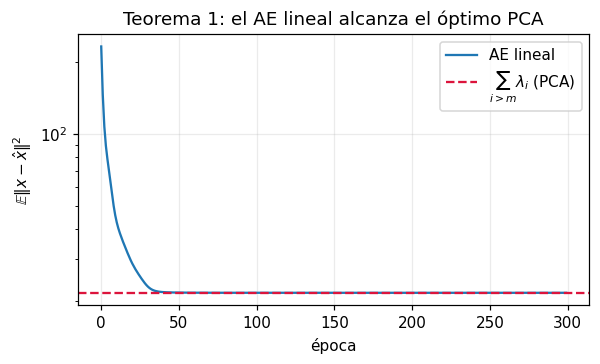

In [3]:
# Gráfico: el error del AE converge al valor de PCA (cota del Teorema 1)
plt.figure(figsize=(6,3.2))
plt.plot(np.array(hist.history["loss"])*l, label="AE lineal")
plt.axhline(lam[m:].sum(), color="crimson", ls="--", label=r"$\sum_{i>m}\lambda_i$ (PCA)")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel(r"$\mathbb{E}\|x-\hat{x}\|^2$")
plt.title("Teorema 1: el AE lineal alcanza el óptimo PCA"); plt.legend(); plt.show()

In [4]:
# ---- Teorema 1 (parte 3): los puntos críticos "equivocados" son SILLAS ----
# Subespacio {v1, v2, v5}: es punto crítico, pero rotar v5 hacia v3 (lambda_3 > lambda_5) DISMINUYE J.
rng = np.random.default_rng(1)
l_, m_ = 8, 3
B = rng.normal(size=(l_, l_)); Sg = B @ B.T + np.eye(l_)
lam_, V_ = np.linalg.eigh(Sg); V_ = V_[:, ::-1]; lam_ = lam_[::-1]

def J_subspace(U):
    Q, _ = np.linalg.qr(U); A = Q @ Q.T
    return np.trace((np.eye(l_) - A) @ Sg)

for t in [0, 0.1, 0.2, 0.4]:
    u = np.cos(t)*V_[:, 4] + np.sin(t)*V_[:, 2]
    print(f"rotación t={t:3.1f}   J = {J_subspace(np.column_stack([V_[:,0], V_[:,1], u])):.4f}")
print("mínimo global sum_{i>m} lambda_i =", lam_[m_:].sum())

rotación t=0.0   J = 17.4298
rotación t=0.1   J = 17.3951
rotación t=0.2   J = 17.2923
rotación t=0.4   J = 16.9016
mínimo global sum_{i>m} lambda_i = 13.946385326930235



#### **Preguntas para discusión**

1. **Estabilidad y reproducibilidad:** ¿Qué ocurre con la distancia $\|\boldsymbol{P}_{AE}-\boldsymbol{P}_{PCA}\|_F$ al repetir el entrenamiento con diferentes semillas aleatorias? ¿Por qué los pesos individuales $\boldsymbol{W}_1$ pueden cambiar aunque la reconstrucción sea equivalente?

2. **Introducción de no linealidad:** Si incorporamos una función de activación no lineal en el codificador, ¿continúa siendo válido el **Teorema 1**? ¿Qué relación existe con el **PCA no lineal**? Véase [4].

3. **Optimización y convergencia:** ¿Por qué, bajo las hipótesis del AE lineal sin restricciones adicionales, se afirma que **no existen mínimos locales subóptimos**, pero el descenso de gradiente puede converger lentamente? Analice el papel de los **puntos silla** y las regiones de gradiente pequeño.



## **I.3. Autoencoders profundos y no lineales**

Los **autoencoders profundos (Deep Autoencoders)** incorporan múltiples capas y **funciones de activación no lineales** para aprender representaciones más complejas que las obtenidas mediante PCA.

- **PCA:** representa los datos mediante **subespacios lineales** de menor dimensión.
- **AE profundo:** puede aproximar estructuras no lineales, incluidas **variedades curvas (*manifolds*)**.
- **Consecuencia:** el **Teorema 1** sobre la optimalidad de PCA no se aplica directamente al modelo no lineal, aunque PCA continúa siendo una referencia para comparar su desempeño.

**Hipótesis de la variedad (*Manifold Hypothesis*).** Plantea que los datos observados en un espacio de alta dimensión $\mathbb{R}^{l}$ pueden concentrarse cerca de una variedad $\mathcal{M}$ cuya **dimensión intrínseca** $m$ es considerablemente menor que $l$:

$$
\boxed{\mathcal{M}\subseteq\mathbb{R}^{l},\qquad m\ll l}
$$

Bajo esta interpretación, el **codificador** puede aprender una representación local de coordenadas de la variedad, mientras que el **decodificador** aproxima la transformación inversa:

$$
\boxed{
\boldsymbol{x}\in\mathcal{M}
\xrightarrow{\;g_\phi\;}
\boldsymbol{z}\in\mathbb{R}^{m}
\xrightarrow{\;f_\theta\;}
\hat{\boldsymbol{x}}\approx\boldsymbol{x}
}
$$

**Interpretación:** el AE profundo busca aprender una **representación latente compacta** que preserve la estructura no lineal de los datos y permita reconstruirlos con un error reducido [6, Cap. 14].


### **Experimento 2 · Reconstrucción de imágenes Fashion-MNIST**

Se cargan imágenes de **28 × 28 píxeles** y se escalan sus intensidades a \([0,1]\). **Qué observar:** imágenes originales frente a las reconstruidas y comparación con PCA.

In [5]:
# ---- Fashion-MNIST ----
(x_tr, y_tr), (x_te, y_te) = keras.datasets.fashion_mnist.load_data()
x_tr = (x_tr.astype("float32")/255.)[..., None]
x_te = (x_te.astype("float32")/255.)[..., None]
x_tr_f = x_tr.reshape(-1, 784); x_te_f = x_te.reshape(-1, 784)
class_names = ["Camiseta","Pantalón","Suéter","Vestido","Abrigo","Sandalia","Camisa","Zapatilla","Bolso","Bota"]
print(x_tr.shape, x_te.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


In [6]:
# Modelo: codificador y decodificador densos para reconstruir imágenes vectorizadas.
def build_dense_ae(latent_dim=32, hidden=(256, 128)):
    inp = keras.Input(shape=(784,))
    h = inp
    for u in hidden:
        h = layers.Dense(u, activation="relu")(h)
    z = layers.Dense(latent_dim, name="z")(h)
    h = z
    for u in reversed(hidden):
        h = layers.Dense(u, activation="relu")(h)
    out = layers.Dense(784, activation="sigmoid")(h)
    ae  = keras.Model(inp, out, name="dense_ae")
    enc = keras.Model(inp, z,   name="encoder")
    return ae, enc

ae, enc = build_dense_ae(latent_dim=32)
ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
ae.summary()
h_ae = ae.fit(x_tr_f, x_tr_f, epochs=15, batch_size=256,
              validation_data=(x_te_f, x_te_f), verbose=2)

Model: "dense_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ z (Dense)                       │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
235/235 - 3s - 13ms/step - loss: 0.3574 - val_loss: 0.3119
Epoch 2/15
235/235 - 2s - 9ms/step - loss: 0.3012 - val_loss: 0.2980
Epoch 3/15
235/235 - 2s - 9ms/step - loss: 0.2927 - val_loss: 0.2919
Epoch 4/15
235/235 - 2s - 9ms/step - loss: 0.2879 - val_loss: 0.2885
Epoch 5/15
235/235 - 2s - 9ms/step - loss: 0.2848 - val_loss: 0.2856
Epoch 6/15
235/235 - 2s - 9ms/step - loss: 0.2819 - val_loss: 0.2831
Epoch 7/15
235/235 - 2s - 9ms/step - loss: 0.2801 - val_loss: 0.2816
Epoch 8/15
235/235 - 2s - 9ms/step - loss: 0.2788 - val_loss: 0.2804
Epoch 9/15
235/235 - 2s - 9ms/step - loss: 0.2777 - val_loss: 0.2805
Epoch 10/15
235/235 - 2s - 9ms/step - loss: 0.2766 - val_loss: 0.2791
Epoch 11/15
235/235 - 2s - 9ms/step - loss: 0.2755 - val_loss: 0.2775
Epoch 12/15
235/235 - 2s - 9ms/step - loss: 0.2748 - val_loss: 0.2769
Epoch 13/15
235/235 - 2s - 9ms/step - loss: 0.2741 - val_loss: 0.2763
Epoch 14/15
235/235 - 2s - 9ms/step - loss: 0.2735 - val_loss: 0.2758
Epoch 15/15
235/235 - 2s - 9

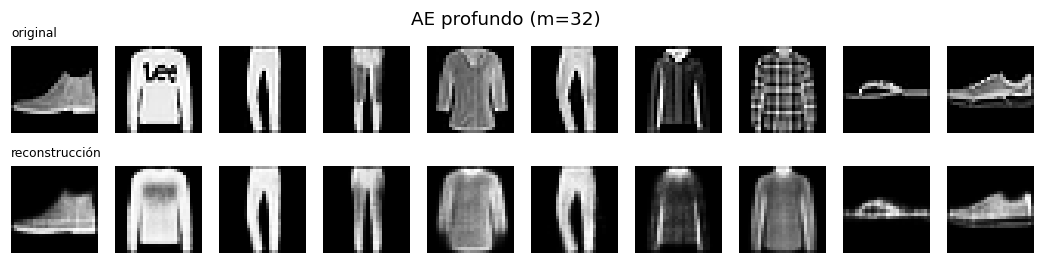

In [7]:
# Figura: comparar imágenes originales (fila superior) y reconstruidas (inferior).
def show_recon(model, x, n=10, title=""):
    rec = model.predict(x[:n], verbose=0).reshape(-1, 28, 28)
    fig, ax = plt.subplots(2, n, figsize=(1.2*n, 2.6))
    for i in range(n):
        ax[0,i].imshow(x[i].reshape(28,28), cmap="gray"); ax[0,i].axis("off")
        ax[1,i].imshow(rec[i], cmap="gray");              ax[1,i].axis("off")
    ax[0,0].set_title("original", fontsize=8, loc="left"); ax[1,0].set_title("reconstrucción", fontsize=8, loc="left")
    fig.suptitle(title); plt.show()

show_recon(ae, x_te_f, title="AE profundo (m=32)")

In [9]:
# ---- Comparación con PCA a igual dimensión latente ----
from sklearn.decomposition import PCA
pca = PCA(n_components=32).fit(x_tr_f)
rec_pca = pca.inverse_transform(pca.transform(x_te_f))
mse_pca = np.mean((x_te_f - rec_pca)**2)
mse_ae  = np.mean((x_te_f - ae.predict(x_te_f, verbose=0))**2)
print(f"MSE PCA(32) = {mse_pca:.5f}   |   MSE AE(32) = {mse_ae:.5f}")

MSE PCA(32) = 0.01514   |   MSE AE(32) = 0.01052


### **Experimento 3 · Visualización del espacio latente**

Se reduce el código a **dos dimensiones** para representar cada imagen como un punto. **Qué observar:** agrupaciones y superposiciones por categoría; la visualización no prueba, por sí misma, separabilidad perfecta.

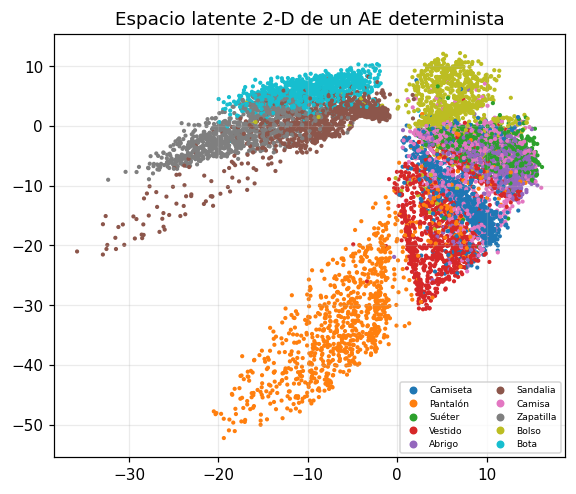

In [10]:
# ---- Visualización 2-D del espacio latente (AE con m=2) ----
ae2, enc2 = build_dense_ae(latent_dim=2)
ae2.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
ae2.fit(x_tr_f, x_tr_f, epochs=15, batch_size=256, verbose=0)
z2 = enc2.predict(x_te_f, verbose=0)
plt.figure(figsize=(6,5))
sc = plt.scatter(z2[:,0], z2[:,1], c=y_te, cmap="tab10", s=3)
plt.legend(sc.legend_elements()[0], class_names, fontsize=6, markerscale=.7, ncol=2)
plt.title("Espacio latente 2-D de un AE determinista"); plt.show()


## **I.4. Autoencoders regularizados**

Los **autoencoders regularizados** incorporan restricciones que favorecen el aprendizaje de representaciones útiles y evitan que modelos **sobrecompletos** ($m\geq l$) o muy expresivos se limiten a reproducir la identidad $\hat{\boldsymbol{x}}=\boldsymbol{x}$.

Estas restricciones actúan como un **sesgo inductivo**, modificando la función de pérdida o el proceso de entrenamiento.

| **Variante** | **Mecanismo de regularización** | **Función de pérdida** |
|---|---|---|
| **Denoising (DAE)** [7] | Añade ruido a la entrada y reconstruye los datos originales. | $\mathbb{E}\|\boldsymbol{x}-f(g(\tilde{\boldsymbol{x}}))\|_2^2$ |
| **Disperso (Sparse AE)** [8] | Penaliza las activaciones del código latente para promover representaciones dispersas. | $\mathcal{J}+\lambda\|\boldsymbol{z}\|_1$ |
| **Contractivo (CAE)** [9] | Penaliza la sensibilidad del codificador frente a pequeñas perturbaciones. | $\mathcal{J}+\lambda\left\|\frac{\partial g}{\partial\boldsymbol{x}}\right\|_F^2$ |

**Elementos de las expresiones:**
- **$\tilde{\boldsymbol{x}}=\boldsymbol{x}+\sigma\boldsymbol{\varepsilon}$:** entrada contaminada con ruido de intensidad $\sigma$, donde $\boldsymbol{\varepsilon}$ representa la perturbación aleatoria.
- **$\boldsymbol{z}=g_\phi(\boldsymbol{x})$:** representación latente; $\|\boldsymbol{z}\|_1$ penaliza activaciones de gran magnitud.
- **$\partial g/\partial\boldsymbol{x}$:** matriz jacobiana del codificador; su norma de Frobenius mide la sensibilidad local.
- **$\lambda\geq0$:** hiperparámetro que controla la intensidad de la regularización.
- **$\mathcal{J}$:** pérdida de reconstrucción del autoencoder convencional.

**Interpretación:** los tres enfoques buscan evitar representaciones triviales, pero mediante mecanismos diferentes: el **DAE** aprende a recuperar información ante perturbaciones, el **Sparse AE** favorece códigos con pocas activaciones y el **CAE** promueve estabilidad local.

**Idea central:** la regularización permite aprender **representaciones latentes más estructuradas y robustas**. La invariancia local es especialmente explícita en el CAE y, bajo ciertas condiciones, en el DAE; no constituye una propiedad garantizada de toda regularización dispersa.



### **Teorema 2 (Alain–Bengio, 2014): el autoencoder regularizado estima el *score***

**Definición 2 (*Score*).** Sea $p(\boldsymbol{x})$ una densidad de probabilidad positiva y diferenciable. Su **función *score*** es:

$$
\boxed{s(\boldsymbol{x})=\nabla_{\boldsymbol{x}}\log p(\boldsymbol{x})
=\frac{\nabla_{\boldsymbol{x}}p(\boldsymbol{x})}{p(\boldsymbol{x})}}
$$

Este campo vectorial indica la **dirección de mayor crecimiento local de la log-densidad**.

**Teorema 2.** Consideremos un **autoencoder denoising (DAE)** con capacidad suficiente, entrenado para minimizar:

$$
\mathcal{J}(r)=\mathbb{E}_{\boldsymbol{x},\boldsymbol{\varepsilon}}
\left[\|r(\tilde{\boldsymbol{x}})-\boldsymbol{x}\|_2^2\right],
\qquad
\tilde{\boldsymbol{x}}=\boldsymbol{x}+\sigma\boldsymbol{\varepsilon},
\quad \boldsymbol{\varepsilon}\sim\mathcal{N}(0,I).
$$

Si $p$ satisface condiciones adecuadas de suavidad e integrabilidad, la **reconstrucción óptima** cumple:

$$
\boxed{
r_\sigma(\boldsymbol{x})
=\boldsymbol{x}+\sigma^2\nabla_{\boldsymbol{x}}\log p_\sigma(\boldsymbol{x})
}
$$

donde $p_\sigma=p*\mathcal{N}(0,\sigma^2I)$ es la **densidad suavizada mediante ruido gaussiano**. En consecuencia:

$$
\boxed{
\lim_{\sigma\to0}
\frac{r_\sigma(\boldsymbol{x})-\boldsymbol{x}}{\sigma^2}
=\nabla_{\boldsymbol{x}}\log p(\boldsymbol{x})
}
$$

**Demostración. ¿Qué queremos probar?** Que el desplazamiento entre la entrada contaminada y su reconstrucción óptima, dividido por $\sigma^2$, permite recuperar el *score* de la distribución.

**Paso 1. Determinar la reconstrucción óptima.** Denotemos por $\boldsymbol{Y}=\boldsymbol{X}+\sigma\boldsymbol{\varepsilon}$ la observación contaminada. Para cada $\boldsymbol{y}$, minimizar el error cuadrático implica:

$$
r_\sigma(\boldsymbol{y})
=\arg\min_{\boldsymbol{a}}
\mathbb{E}\left[\|\boldsymbol{X}-\boldsymbol{a}\|_2^2\mid\boldsymbol{Y}=\boldsymbol{y}\right].
$$

Al expandir el cuadrado y derivar respecto a $\boldsymbol{a}$:

$$
\nabla_{\boldsymbol{a}}\mathbb{E}[\|\boldsymbol{X}-\boldsymbol{a}\|_2^2\mid\boldsymbol{Y}=\boldsymbol{y}]
=2\left(\boldsymbol{a}-\mathbb{E}[\boldsymbol{X}\mid\boldsymbol{Y}=\boldsymbol{y}]\right).
$$

Igualando a cero, obtenemos:

$$
\boxed{r_\sigma(\boldsymbol{y})=\mathbb{E}[\boldsymbol{X}\mid\boldsymbol{Y}=\boldsymbol{y}]}
$$

**Paso 2. Escribir la densidad suavizada.** Sea $\varphi_\sigma$ la densidad gaussiana del ruido. Por convolución:

$$
p_\sigma(\boldsymbol{y})
=\int p(\boldsymbol{x})\varphi_\sigma(\boldsymbol{y}-\boldsymbol{x})\,d\boldsymbol{x}.
$$

**Paso 3. Derivar la densidad.** Utilizando la derivada de una gaussiana:

$$
\nabla_{\boldsymbol{y}}\varphi_\sigma(\boldsymbol{y}-\boldsymbol{x})
=\frac{\boldsymbol{x}-\boldsymbol{y}}{\sigma^2}
\varphi_\sigma(\boldsymbol{y}-\boldsymbol{x}).
$$

Por tanto, derivando bajo la integral:

$$
\nabla_{\boldsymbol{y}}p_\sigma(\boldsymbol{y})
=\frac{1}{\sigma^2}
\int(\boldsymbol{x}-\boldsymbol{y})
p(\boldsymbol{x})\varphi_\sigma(\boldsymbol{y}-\boldsymbol{x})\,d\boldsymbol{x}.
$$

**Paso 4. Relacionar el resultado con la reconstrucción.** Dividimos por $p_\sigma(\boldsymbol{y})$ y aplicamos la fórmula de Bayes:

$$
\begin{aligned}
\nabla_{\boldsymbol{y}}\log p_\sigma(\boldsymbol{y})
&=\frac{\nabla_{\boldsymbol{y}}p_\sigma(\boldsymbol{y})}{p_\sigma(\boldsymbol{y})}\\
&=\frac{1}{\sigma^2}
\left(\mathbb{E}[\boldsymbol{X}\mid\boldsymbol{Y}=\boldsymbol{y}]
-\boldsymbol{y}\right)\\
&=\frac{r_\sigma(\boldsymbol{y})-\boldsymbol{y}}{\sigma^2}.
\end{aligned}
$$

Despejando:

$$
\boxed{r_\sigma(\boldsymbol{y})
=\boldsymbol{y}+\sigma^2\nabla_{\boldsymbol{y}}\log p_\sigma(\boldsymbol{y})}
$$

Finalmente, si $p_\sigma\to p$ y $\nabla p_\sigma\to\nabla p$ cuando $\sigma\to0$, con $p(\boldsymbol{y})>0$:

$$
\boxed{
\lim_{\sigma\to0}\frac{r_\sigma(\boldsymbol{y})-\boldsymbol{y}}{\sigma^2}
=\nabla_{\boldsymbol{y}}\log p(\boldsymbol{y})
}
$$

Queda demostrado que el **DAE óptimo estima exactamente el *score* de la densidad suavizada** y, en el límite de ruido pequeño, recupera el *score* de la distribución original. Esto conecta la reconstrucción con el aprendizaje de la estructura probabilística de los datos.


#### **· Teorema 2 (Alain–Bengio)**

**Objetivo.** Justificar que la reconstrucción óptima de un autoencoder que elimina ruido proporciona una estimación del **score**, $\nabla\log p$, es decir, de la dirección de mayor crecimiento de la logdensidad.

**Paso 1. Definir observación y ruido.** Sean $x\sim p(x)$, $\varepsilon\sim\mathcal N(0,I)$ independientes, $y=x+\sigma\varepsilon$ y $\varphi_\sigma(y-x)$ la densidad gaussiana del ruido. La densidad de la observación es

$$p_\sigma(y)=\int p(x)\varphi_\sigma(y-x)\,dx.$$

**Paso 2. Minimizar el error cuadrático condicional.** Para una entrada ruidosa fija $y$, definimos $F_y(a)=\mathbb E[\|x-a\|^2\mid y]$. Al derivar respecto al vector $a$,

$$\nabla_aF_y(a)=2\big(a-\mathbb E[x\mid y]\big).$$

La matriz hessiana es $2I\succ0$: existe un mínimo único, dado por

$$\boxed{r_\sigma^*(y)=\mathbb E[x\mid y]}.$$

**Paso 3. Aplicar Bayes.** Utilizando $p(x\mid y)=p(x)\varphi_\sigma(y-x)/p_\sigma(y)$,

$$r_\sigma^*(y)=\frac{\int x\,p(x)\varphi_\sigma(y-x)\,dx}{p_\sigma(y)}.$$

**Paso 4. Diferenciar la densidad suavizada.** Para una gaussiana isotrópica,

$$\nabla_y\varphi_\sigma(y-x)=\frac{x-y}{\sigma^2}\varphi_\sigma(y-x).$$

Suponiendo regularidad suficiente para intercambiar derivación e integración,

$$\begin{aligned}
\nabla_y p_\sigma(y)
&=\int p(x)\nabla_y\varphi_\sigma(y-x)\,dx\\
&=\frac{1}{\sigma^2}\bigg[\int xp(x)\varphi_\sigma(y-x)\,dx-yp_\sigma(y)\bigg]\\
&=\frac{p_\sigma(y)}{\sigma^2}\big(r_\sigma^*(y)-y\big).
\end{aligned}$$

**Paso 5. Dividir por la densidad.** Como $\nabla\log p_\sigma=(\nabla p_\sigma)/p_\sigma$,

$$\boxed{r_\sigma^*(y)=y+\sigma^2\nabla_y\log p_\sigma(y)}.$$

Es la **identidad de Tweedie**: el desplazamiento entre entrada ruidosa y reconstrucción es proporcional al score de la distribución *suavizada*.

**Paso 6. Recuperar el score original.** Si $p$ es suficientemente suave, positiva en el punto considerado y $p_\sigma$, $\nabla p_\sigma$ convergen localmente a $p$, $\nabla p$, respectivamente, entonces

$$\boxed{\lim_{\sigma\to0}\frac{r_\sigma^*(y)-y}{\sigma^2}=\nabla_y\log p(y)}.\qquad\blacksquare$$

> **Interpretación:** para ruido no nulo se obtiene el score de $p_\sigma$, **no directamente** el de $p$. La igualdad es exacta para el reconstructor ideal bajo ruido gaussiano; las redes entrenadas solo lo aproximan. Esta prueba es compatible con el vínculo entre autoencoders regularizados y score estudiado por Alain y Bengio (2014, [10]).


### **Experimento 4 · Autoencoder regularizado y *score***

El experimento unidimensional contrasta una relación teórica con una estimación numérica. **Qué observar:** la correspondencia entre reconstrucción y gradiente de la logdensidad, junto con los supuestos del teorema.

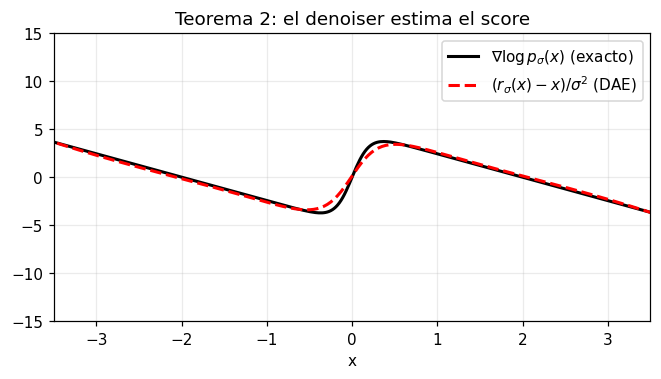

In [11]:
# ---- Verificación numérica del Teorema 2 en 1-D (mezcla gaussiana, score exacto conocido) ----
# p(x) = 0.5 N(-2, 0.5^2) + 0.5 N(2, 0.5^2).  Con ruido sigma: p_sigma = mezcla con var 0.5^2 + sigma^2.
mus, s0, sigma = np.array([-2., 2.]), 0.5, 0.4

def sample_p(n):
    k = np.random.randint(0, 2, n)
    return (mus[k] + s0*np.random.randn(n)).astype("float32")

def score_p_sigma(x):
    v = s0**2 + sigma**2
    comp = [np.exp(-0.5*(x-mu)**2/v) for mu in mus]
    num = sum(c*(-(x-mu)/v) for c, mu in zip(comp, mus))
    return num / sum(comp)

xs = sample_p(200_000)
xt = xs + sigma*np.random.randn(len(xs)).astype("float32")

dae = keras.Sequential([keras.Input(shape=(1,)),
                        layers.Dense(128, activation="tanh"),
                        layers.Dense(128, activation="tanh"),
                        layers.Dense(1)])
dae.compile(optimizer=keras.optimizers.Adam(2e-3), loss="mse")
dae.fit(xt[:, None], xs[:, None], epochs=15, batch_size=1024, verbose=0)

grid = np.linspace(-4, 4, 400).astype("float32")
score_est   = (dae.predict(grid[:, None], verbose=0)[:, 0] - grid) / sigma**2
score_exact = score_p_sigma(grid)

plt.figure(figsize=(7,3.4))
plt.plot(grid, score_exact, "k", lw=2, label=r"$\nabla\log p_\sigma(x)$ (exacto)")
plt.plot(grid, score_est, "r--", lw=2, label=r"$(r_\sigma(x)-x)/\sigma^2$ (DAE)")
plt.xlim(-3.5, 3.5); plt.ylim(-15, 15)
plt.title("Teorema 2: el denoiser estima el score"); plt.xlabel("x"); plt.legend(); plt.show()

### **Experimento 5 · Eliminación de ruido**

El *denoising autoencoder* aprende a recuperar imágenes a partir de versiones contaminadas. **Qué observar:** entrada ruidosa y reconstrucción para juzgar cuánto ruido se elimina y qué detalles se pierden.

Epoch 1/8
235/235 - 9s - 40ms/step - loss: 0.3814 - val_loss: 0.3043
Epoch 2/8
235/235 - 8s - 35ms/step - loss: 0.2947 - val_loss: 0.2913
Epoch 3/8
235/235 - 9s - 38ms/step - loss: 0.2859 - val_loss: 0.2856
Epoch 4/8
235/235 - 10s - 42ms/step - loss: 0.2812 - val_loss: 0.2821
Epoch 5/8
235/235 - 10s - 42ms/step - loss: 0.2784 - val_loss: 0.2797
Epoch 6/8
235/235 - 9s - 40ms/step - loss: 0.2764 - val_loss: 0.2781
Epoch 7/8
235/235 - 10s - 41ms/step - loss: 0.2749 - val_loss: 0.2769
Epoch 8/8
235/235 - 10s - 41ms/step - loss: 0.2737 - val_loss: 0.2759


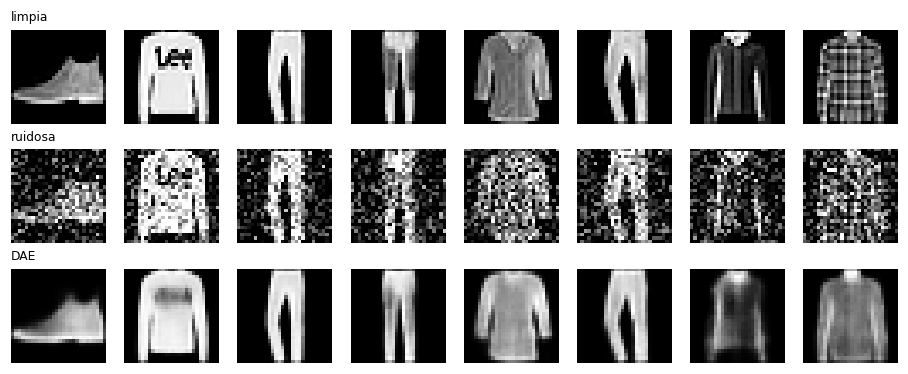

In [12]:
# ---- DAE sobre Fashion-MNIST ----
def build_conv_dae(latent_dim=64):
    inp = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)
    h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Flatten()(h)
    z = layers.Dense(latent_dim, name="z")(h)
    h = layers.Dense(7*7*64, activation="relu")(z)
    h = layers.Reshape((7, 7, 64))(h)
    h = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)
    out = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(h)
    return keras.Model(inp, out, name="conv_dae")

dae_img = build_conv_dae()
dae_img.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")

noise_std = 0.3
def corrupt(x): return np.clip(x + noise_std*np.random.randn(*x.shape).astype("float32"), 0., 1.)

x_tr_noisy = corrupt(x_tr)
x_te_noisy = corrupt(x_te)
dae_img.fit(x_tr_noisy, x_tr, epochs=8, batch_size=256, validation_data=(x_te_noisy, x_te), verbose=2)

n = 8
den = dae_img.predict(x_te_noisy[:n], verbose=0)
fig, ax = plt.subplots(3, n, figsize=(1.3*n, 4))
for i in range(n):
    for r, im in enumerate([x_te[i], x_te_noisy[i], den[i]]):
        ax[r, i].imshow(im.squeeze(), cmap="gray"); ax[r, i].axis("off")
for r, t in enumerate(["limpia", "ruidosa", "DAE"]): ax[r, 0].set_title(t, fontsize=8, loc="left")
plt.show()

In [13]:
# ---- AE contractivo (CAE): penaliza ||dz/dx||_F^2 calculado con autodiff ----
class ContractiveAE(keras.Model):
    def __init__(self, latent=32, lam=1e-1):
        super().__init__()
        self.lam = lam
        self.enc = keras.Sequential([layers.Dense(128, activation="relu"),
                                     layers.Dense(latent, activation="sigmoid")])
        self.dec = keras.Sequential([layers.Dense(128, activation="relu"),
                                     layers.Dense(784)])                 # logits
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.rec_tracker  = keras.metrics.Mean(name="recon")
        self.jac_tracker  = keras.metrics.Mean(name="jac")

    @property
    def metrics(self): return [self.loss_tracker, self.rec_tracker, self.jac_tracker]

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data      # x: (B, 784)
        with tf.GradientTape() as outer:
            with tf.GradientTape() as inner:
                inner.watch(x)
                z = self.enc(x)                                       # (B, m)
            J = inner.batch_jacobian(z, x)                            # (B, m, 784)
            jac = tf.reduce_mean(tf.reduce_sum(tf.square(J), axis=[1, 2]))
            logits = self.dec(z)
            rec = tf.reduce_mean(tf.reduce_sum(
                tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=logits), axis=1))
            loss = rec + self.lam * jac
        grads = outer.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(loss); self.rec_tracker.update_state(rec); self.jac_tracker.update_state(jac)
        return {m.name: m.result() for m in self.metrics}

    def call(self, x): return tf.sigmoid(self.dec(self.enc(x)))

cae = ContractiveAE(latent=32, lam=1e-1)
cae.compile(optimizer=keras.optimizers.Adam(1e-3))
cae.fit(x_tr_f, epochs=5, batch_size=256, verbose=2)

# ---- AE disperso (sparse): regularizador L1 sobre la actividad del código ----
sp_in  = keras.Input(shape=(784,))
sp_z   = layers.Dense(128, activation="relu", activity_regularizer=keras.regularizers.l1(1e-5))(sp_in)
sp_out = layers.Dense(784, activation="sigmoid")(sp_z)
sparse_ae = keras.Model(sp_in, sp_out)
sparse_ae.compile(optimizer="adam", loss="binary_crossentropy")
sparse_ae.fit(x_tr_f, x_tr_f, epochs=8, batch_size=256, verbose=0)

mse = lambda m: np.mean((x_te_f - m.predict(x_te_f, verbose=0))**2)
print(f"MSE test  |  AE denso: {mse(ae):.5f}  |  Contractivo: {mse(cae):.5f}  |  Sparse: {mse(sparse_ae):.5f}")

Epoch 1/5


E0000 00:00:1795148809.941766  346919 util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


235/235 - 6s - 25ms/step - jac: 0.8796 - loss: 339.0044 - recon: 338.9164
Epoch 2/5
235/235 - 6s - 24ms/step - jac: 1.5456 - loss: 261.6444 - recon: 261.4899
Epoch 3/5
235/235 - 5s - 21ms/step - jac: 1.6827 - loss: 248.9565 - recon: 248.7881
Epoch 4/5
235/235 - 5s - 22ms/step - jac: 1.7805 - loss: 244.1830 - recon: 244.0050
Epoch 5/5
235/235 - 5s - 21ms/step - jac: 1.8807 - loss: 240.7557 - recon: 240.5676
MSE test  |  AE denso: 0.01052  |  Contractivo: 0.02107  |  Sparse: 0.02800



## **I.5. Límite del AE como modelo generativo: motivación de los VAE**

Un **autoencoder (AE) determinista** aprende una representación latente $\boldsymbol{z}=g_\phi(\boldsymbol{x})$, pero **no modela explícitamente una distribución de probabilidad** sobre dicho espacio.

- **Limitación:** al generar un código $\boldsymbol{z}$ arbitrario, no se garantiza que su reconstrucción $f_\theta(\boldsymbol{z})$ corresponda a una observación realista.
- **Consecuencia:** el espacio latente puede contener regiones poco representadas, donde el decodificador produce resultados sin sentido.
- **Solución:** los **autoencoders variacionales (VAE)** introducen un modelo probabilístico y regularizan el espacio latente mediante una distribución previa, habitualmente $p(\boldsymbol{z})=\mathcal{N}(\boldsymbol{0},I)$.

**Idea central:** mientras el **AE aprende a comprimir y reconstruir**, el **VAE aprende una representación probabilística** que permite generar nuevas observaciones mediante:

$$
\boxed{
\boldsymbol{z}\sim p(\boldsymbol{z})
\quad\longrightarrow\quad
\boldsymbol{x}\sim p_\theta(\boldsymbol{x}\mid\boldsymbol{z})
}
$$

Esta transición fundamenta el estudio de los **modelos generativos variacionales**.


### **Experimento 6 · Límite generativo del AE convencional**

Se decodifican puntos elegidos en el espacio latente. **Qué observar:** la calidad de muestras ubicadas en regiones poco representadas durante el entrenamiento.

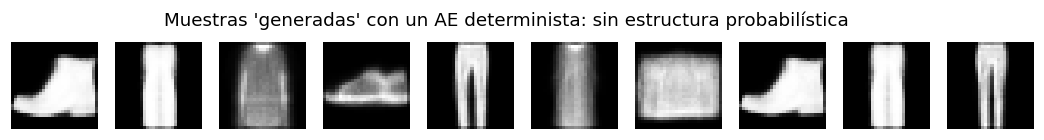

In [14]:
# Decodificar puntos latentes aleatorios del AE determinista (m=2) -> basura / regiones vacías
zs = np.random.uniform(z2.min(0), z2.max(0), size=(10, 2)).astype("float32")
dec2 = keras.Model(ae2.get_layer("z").output, ae2.output)  # no sirve directamente; reconstruimos decodificador
z_in = keras.Input(shape=(2,)); h = z_in
for lay in ae2.layers[ae2.layers.index(ae2.get_layer("z"))+1:]: h = lay(h)
decoder2 = keras.Model(z_in, h)
imgs = decoder2.predict(zs, verbose=0).reshape(-1, 28, 28)
fig, ax = plt.subplots(1, 10, figsize=(12, 1.4))
for i in range(10): ax[i].imshow(imgs[i], cmap="gray"); ax[i].axis("off")
fig.suptitle("Muestras 'generadas' con un AE determinista: sin estructura probabilística"); plt.show()

**Tres problemas del AE determinista como generador:**

1. **Huecos:** el espacio latente tiene regiones sin datos; el decodificador no está entrenado allí.
2. **Sin densidad:** no hay \(p(\boldsymbol{z})\) para muestrear ni para evaluar verosimilitudes.
3. **Sin continuidad garantizada:** puntos latentes cercanos pueden decodificar a imágenes muy distintas.



# **PARTE II. Autoencoders variacionales (VAE)**

## **II.1. Modelos de variable latente e inferencia variacional**

**Definición 3 (Modelo de variable latente).** Un **modelo generativo probabilístico** introduce una variable latente $\boldsymbol{z}\in\mathbb{R}^m$ para explicar cómo se generan las observaciones $\boldsymbol{x}\in\mathbb{R}^l$. Su distribución conjunta se factoriza como:

$$
\boxed{
p_\theta(\boldsymbol{x},\boldsymbol{z})
=p_\theta(\boldsymbol{x}\mid\boldsymbol{z})p(\boldsymbol{z})
}
$$

donde:

- **Distribución previa (*prior*):** $p(\boldsymbol{z})=\mathcal{N}(\boldsymbol{0},I)$, que describe la distribución inicial de las variables latentes.
- **Decodificador probabilístico:** $p_\theta(\boldsymbol{x}\mid\boldsymbol{z})$, cuyos parámetros son aprendidos por una red neuronal.
- **Parámetros $\theta$:** pesos y sesgos entrenables del modelo generativo.

El **proceso generativo** consiste en muestrear $\boldsymbol{z}\sim p(\boldsymbol{z})$ y posteriormente generar $\boldsymbol{x}\sim p_\theta(\boldsymbol{x}\mid\boldsymbol{z})$.

**Verosimilitud marginal (evidencia).** La probabilidad de una observación se obtiene integrando todas las posibles variables latentes:

$$
\boxed{
p_\theta(\boldsymbol{x})
=\int_{\mathbb{R}^m}
p_\theta(\boldsymbol{x}\mid\boldsymbol{z})
p(\boldsymbol{z})\,d\boldsymbol{z}
}
$$

**Problema fundamental.** Con decodificadores neuronales no lineales, esta integral generalmente resulta **intratable analíticamente**. En consecuencia, también es difícil calcular la **distribución posterior verdadera**, definida mediante el teorema de Bayes:

$$
\boxed{
p_\theta(\boldsymbol{z}\mid\boldsymbol{x})
=\frac{p_\theta(\boldsymbol{x}\mid\boldsymbol{z})p(\boldsymbol{z})}
{p_\theta(\boldsymbol{x})}
}
$$

Esto dificulta maximizar directamente $\log p_\theta(\boldsymbol{x})$ y aplicar EM exacto, motivando el uso de **inferencia variacional**.

**Definición 4 (Inferencia variacional amortizada).** Consiste en aproximar la posterior verdadera mediante una distribución parametrizada:

$$
q_\phi(\boldsymbol{z}\mid\boldsymbol{x})
\approx p_\theta(\boldsymbol{z}\mid\boldsymbol{x}).
$$

El **codificador probabilístico** utiliza una única red neuronal con parámetros $\phi$ para producir la aproximación correspondiente a cada observación, evitando optimizar parámetros variacionales independientes para cada dato [15, 17].

Habitualmente, se utiliza una **distribución gaussiana con matriz de covarianza diagonal**:

$$
\boxed{
q_\phi(\boldsymbol{z}\mid\boldsymbol{x})
=\mathcal{N}\left(
\boldsymbol{z};
\boldsymbol{\mu}_\phi(\boldsymbol{x}),
\operatorname{diag}\left(\boldsymbol{\sigma}_\phi^2(\boldsymbol{x})\right)
\right)
}
$$

donde:
- **$\boldsymbol{\mu}_\phi(\boldsymbol{x})$:** vector de medias de la distribución latente.
- **$\boldsymbol{\sigma}_\phi^2(\boldsymbol{x})$:** vector de varianzas, cuyos valores deben ser positivos.
- **$\operatorname{diag}(\cdot)$:** construye una matriz diagonal a partir de las varianzas.

### **Comparación entre AE y VAE**

| **Componente** | **Autoencoder (AE)** | **Autoencoder variacional (VAE)** |
|---|---|---|
| **Codificador** | $\boldsymbol{z}=g_\phi(\boldsymbol{x})$ | $q_\phi(\boldsymbol{z}\mid\boldsymbol{x})$ |
| **Representación** | Vector determinista | Distribución probabilística |
| **Decodificador** | $f_\theta(\boldsymbol{z})$ | $p_\theta(\boldsymbol{x}\mid\boldsymbol{z})$ |
| **Espacio latente** | Sin distribución previa explícita | Regularizado hacia $p(\boldsymbol{z})$ |
| **Optimización** | Error de reconstrucción | Maximización de la ELBO |
| **Generación** | Sin mecanismo probabilístico explícito | Muestreo desde $p(\boldsymbol{z})$ |

**Idea central:** mientras el **AE convencional** aprende una transformación para comprimir y reconstruir datos, el **VAE** aprende un modelo probabilístico que permite **aproximar la distribución de los datos y generar nuevas observaciones**. La herramienta matemática fundamental para su entrenamiento será la **cota inferior de la evidencia (ELBO)**.


### **Figura 2 · Arquitectura probabilística de un VAE**


```{figure} imgs/autoencoder_VAE.png
:width: 80%
:align: center
:name: fig-autoencoder-vae

**Figura. Arquitectura de un Autoencoder Variacional (VAE).** Codificador probabilístico, espacio latente, muestreo reparametrizado y decodificador.
```


**Lectura del esquema:** entrada $x$ → codificador $q_\phi$ → parámetros $(\mu,\log\sigma^2)$ → muestra $z=\mu+\sigma\odot\varepsilon$ con $\varepsilon\sim\mathcal N(0,I)$ → decodificador $p_\theta(x\mid z)$ → reconstrucción. La función objetivo combina **reconstrucción** y **divergencia KL**.



## **II.2. La cota inferior de la evidencia (ELBO)**

### **Teorema 3. Descomposición de la evidencia y ELBO**

**Enunciado.** Sea $p_\theta(\boldsymbol{x},\boldsymbol{z})$ un modelo generativo con posterior $p_\theta(\boldsymbol{z}\mid\boldsymbol{x})$, y sea $q_\phi(\boldsymbol{z}\mid\boldsymbol{x})$ una distribución aproximada cuyo soporte está contenido en el de la posterior. Entonces:

$$
\boxed{
\log p_\theta(\boldsymbol{x})
=\mathcal{L}(\theta,\phi;\boldsymbol{x})
+D_{KL}\left(q_\phi(\boldsymbol{z}\mid\boldsymbol{x})
\|p_\theta(\boldsymbol{z}\mid\boldsymbol{x})\right)
}
$$

donde la **cota inferior de la evidencia (ELBO)** se define mediante:

$$
\boxed{
\mathcal{L}(\theta,\phi;\boldsymbol{x})
=\underbrace{\mathbb{E}_{q_\phi}
[\log p_\theta(\boldsymbol{x}\mid\boldsymbol{z})]}_{\text{Reconstrucción}}
-\underbrace{D_{KL}(q_\phi(\boldsymbol{z}\mid\boldsymbol{x})
\|p(\boldsymbol{z}))}_{\text{Regularización}}
}
$$

**Demostración. ¿Qué queremos probar?**
- **(i)** Que la ELBO es una cota inferior de $\log p_\theta(\boldsymbol{x})$.
- **(ii)** Que maximizar la ELBO respecto a $\phi$, con $\theta$ fijo, minimiza la divergencia entre la posterior aproximada y la verdadera.
- **(iii)** Que maximizar la ELBO respecto a $\theta$ mejora el objetivo variacional utilizado para aprender el modelo generativo.

**Paso 1. Partimos de la divergencia de Kullback–Leibler (KL).** Por definición:

$$
D_{KL}(q_\phi\|p_\theta)
=\mathbb{E}_{q_\phi}
\left[\log\frac{q_\phi(\boldsymbol{z}\mid\boldsymbol{x})}
{p_\theta(\boldsymbol{z}\mid\boldsymbol{x})}\right].
$$

Aquí $p_\theta$ representa la posterior verdadera.

**Paso 2. Aplicamos el teorema de Bayes.** Sabemos que:

$$
p_\theta(\boldsymbol{z}\mid\boldsymbol{x})
=\frac{p_\theta(\boldsymbol{x},\boldsymbol{z})}
{p_\theta(\boldsymbol{x})}.
$$

Sustituyendo y utilizando las propiedades del logaritmo:

$$
\begin{aligned}
D_{KL}(q_\phi\|p_\theta)
&=\mathbb{E}_{q_\phi}
\left[\log q_\phi(\boldsymbol{z}\mid\boldsymbol{x})
-\log p_\theta(\boldsymbol{x},\boldsymbol{z})
+\log p_\theta(\boldsymbol{x})\right]\\
&=\mathbb{E}_{q_\phi}[\log q_\phi]
-\mathbb{E}_{q_\phi}[\log p_\theta(\boldsymbol{x},\boldsymbol{z})]
+\log p_\theta(\boldsymbol{x}).
\end{aligned}
$$

El último término sale de la esperanza porque **no depende de $\boldsymbol{z}$**.

**Paso 3. Despejamos la log-verosimilitud marginal.**

$$
\log p_\theta(\boldsymbol{x})
=\underbrace{\mathbb{E}_{q_\phi}
[\log p_\theta(\boldsymbol{x},\boldsymbol{z})
-\log q_\phi(\boldsymbol{z}\mid\boldsymbol{x})]}_{\mathcal{L}(\theta,\phi;\boldsymbol{x})}
+D_{KL}(q_\phi\|p_\theta).
$$

**Paso 4. Obtenemos la expresión de la ELBO.** Como la distribución conjunta se factoriza según:

$$
p_\theta(\boldsymbol{x},\boldsymbol{z})
=p_\theta(\boldsymbol{x}\mid\boldsymbol{z})p(\boldsymbol{z}),
$$

sustituimos en la definición de $\mathcal{L}$:

$$
\begin{aligned}
\mathcal{L}
&=\mathbb{E}_{q_\phi}
[\log p_\theta(\boldsymbol{x}\mid\boldsymbol{z})]
+\mathbb{E}_{q_\phi}
\left[\log\frac{p(\boldsymbol{z})}
{q_\phi(\boldsymbol{z}\mid\boldsymbol{x})}\right]\\
&=\boxed{\mathbb{E}_{q_\phi}
[\log p_\theta(\boldsymbol{x}\mid\boldsymbol{z})]
-D_{KL}(q_\phi\|p)}.
\end{aligned}
$$

**Paso 5. Demostramos las tres consecuencias.**

- **(i) Cota inferior:** como $D_{KL}(q_\phi\|p_\theta)\geq0$, necesariamente $\boxed{\mathcal{L}\leq\log p_\theta(\boldsymbol{x})}$. La igualdad ocurre si y solo si ambas posteriores coinciden casi en todas partes.
- **(ii) Inferencia variacional:** con $\theta$ fijo, $\log p_\theta(\boldsymbol{x})$ es constante respecto a $\phi$. Por tanto, $\boxed{\max_\phi\mathcal{L}\Longleftrightarrow\min_\phi D_{KL}(q_\phi\|p_\theta)}$.
- **(iii) Aprendizaje generativo:** al maximizar $\mathcal{L}$ respecto a $\theta$, se eleva la cota inferior de la log-verosimilitud, aunque esto no garantiza que la log-verosimilitud verdadera aumente en cada actualización.

**Conclusión.** Queda demostrado que **maximizar la ELBO** permite entrenar un VAE sin calcular explícitamente la posterior verdadera. Su objetivo combina dos componentes fundamentales: **reconstruir adecuadamente los datos** y **regularizar la distribución latente** para aproximarla a la distribución previa.

**Idea central:** la ELBO conecta matemáticamente la **inferencia probabilística**, la **reconstrucción de datos** y el **aprendizaje de representaciones latentes**.



#### **Demostración detallada · Teorema 3 (ELBO)**

**Objetivo.** Construir una función objetivo entrenable para un VAE y demostrar por qué es una **cota inferior** de la log-verosimilitud, cuantificando exactamente la diferencia entre ambas.

**Paso 1. Factorización probabilística.** Para un dato $x$ fijo y una variable latente $z$,

$$p_\theta(x,z)=p_\theta(x\mid z)p(z)=p_\theta(z\mid x)p_\theta(x).$$

Tomamos logaritmos y despejamos:

$$\log p_\theta(x)=\log p_\theta(x,z)-\log p_\theta(z\mid x).$$

**Paso 2. Introducir la distribución aproximada.** Integramos respecto de $q_\phi(z\mid x)$ y sumamos/restamos $\log q_\phi(z\mid x)$:

$$\begin{aligned}
\log p_\theta(x)
&=\mathbb E_q\left[\log\frac{p_\theta(x,z)}{q_\phi(z\mid x)}\right]
+\mathbb E_q\left[\log\frac{q_\phi(z\mid x)}{p_\theta(z\mid x)}\right]\\
&=\mathcal L(\theta,\phi;x)+D_{KL}\big(q_\phi(z\mid x)\|p_\theta(z\mid x)\big).
\end{aligned}$$

**Paso 3. Identificar los dos términos del ELBO.** Sustituyendo $p_\theta(x,z)=p_\theta(x\mid z)p(z)$,

$$\boxed{\mathcal L=\underbrace{\mathbb E_q[\log p_\theta(x\mid z)]}_{\text{reconstrucción}}
-\underbrace{D_{KL}(q_\phi(z\mid x)\|p(z))}_{\text{regularización}}}.$$

**Paso 4. Demostrar la desigualdad.** La divergencia KL es no negativa por Gibbs. Por tanto,

$$\boxed{\mathcal L(\theta,\phi;x)\le\log p_\theta(x)}.$$

La igualdad ocurre **si y solo si** $q_\phi(z\mid x)=p_\theta(z\mid x)$ casi en todas partes. Para $\theta$ fijo, maximizar $\mathcal L$ respecto de $\phi$ equivale a minimizar la KL a la posterior verdadera; si también cambia $\theta$, cambian ambas cantidades y se optimiza la cota, no necesariamente la verosimilitud exacta.

**Paso 5. Verificación alternativa mediante Jensen.** Como $\log$ es cóncava y suponemos que $q$ tiene el soporte requerido para la identidad de importancia,

$$\log p_\theta(x)=\log\mathbb E_q\!\left[\frac{p_\theta(x,z)}{q_\phi(z\mid x)}\right]
\ge\mathbb E_q\!\left[\log\frac{p_\theta(x,z)}{q_\phi(z\mid x)}\right]=\mathcal L.\qquad\blacksquare$$

> **Por qué importa:** la prueba permite interpretar el entrenamiento como equilibrio entre calidad de reconstrucción y regularidad del espacio latente. **Guía:** Kingma y Welling (2014, [15], y 2019, [19]).


### **Verificación numérica · Identidad del ELBO**

Se utiliza un modelo conjugado con soluciones conocidas para comparar evidencia, cota inferior y divergencia KL.

In [15]:
# ---- Verificación numérica del Teorema 3 en un modelo conjugado con solución cerrada ----
# p(z)=N(0,1), p(x|z)=N(z,1)  =>  p(x)=N(0,2),  p(z|x)=N(x/2, 1/2).  q(z|x)=N(qm, qs^2) arbitrario.
rng = np.random.default_rng(0)
x0, qm, qs = 1.5, 0.2, 1.0

log_px = -0.5*(np.log(2*np.pi*2) + x0**2/2)                       # log p(x) exacta
z = qm + qs*rng.normal(size=2_000_000)
log_joint = -0.5*(np.log(2*np.pi)+z**2) - 0.5*(np.log(2*np.pi)+(x0-z)**2)
log_q     = -0.5*(np.log(2*np.pi*qs**2) + ((z-qm)/qs)**2)
elbo      = np.mean(log_joint - log_q)

pm, ps2 = x0/2, 0.5                                                # posterior exacta
kl_post = np.log(np.sqrt(ps2)/qs) + (qs**2 + (qm-pm)**2)/(2*ps2) - 0.5

print(f"log p(x)            = {log_px:.5f}")
print(f"ELBO                = {elbo:.5f}")
print(f"KL(q || p(z|x))     = {kl_post:.5f}")
print(f"ELBO + KL           = {elbo+kl_post:.5f}   <- coincide con log p(x) (Teorema 3)")
print(f"Brecha log p - ELBO = {log_px-elbo:.5f}   >= 0")

log p(x)            = -1.82801
ELBO                = -2.28278
KL(q || p(z|x))     = 0.45593
ELBO + KL           = -1.82685   <- coincide con log p(x) (Teorema 3)
Brecha log p - ELBO = 0.45477   >= 0


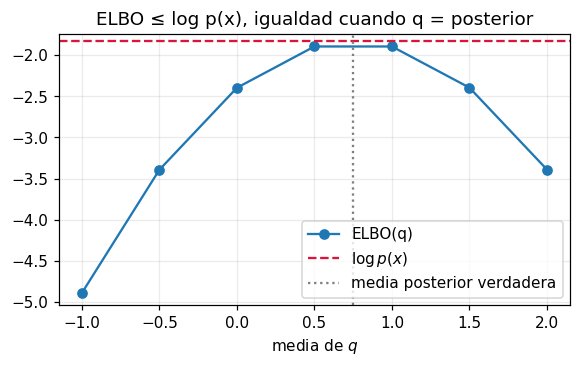

In [16]:
# ---- La brecha se anula cuando q = posterior verdadera ----
qms = np.linspace(-1, 2, 7)
rows = []
for qm_ in qms:
    qs_ = np.sqrt(0.5)
    z = qm_ + qs_*rng.normal(size=500_000)
    lj = -0.5*(np.log(2*np.pi)+z**2) - 0.5*(np.log(2*np.pi)+(x0-z)**2)
    lq = -0.5*(np.log(2*np.pi*qs_**2)+((z-qm_)/qs_)**2)
    rows.append(np.mean(lj-lq))
plt.figure(figsize=(6,3.2))
plt.plot(qms, rows, "o-", label="ELBO(q)")
plt.axhline(log_px, color="crimson", ls="--", label=r"$\log p(x)$")
plt.axvline(pm, color="gray", ls=":", label="media posterior verdadera")
plt.xlabel(r"media de $q$"); plt.title("ELBO ≤ log p(x), igualdad cuando q = posterior"); plt.legend(); plt.show()


## **II.3. La pérdida del VAE y la divergencia KL gaussiana**

En un **autoencoder variacional (VAE)** se utiliza habitualmente una **posterior aproximada gaussiana** y una distribución previa normal estándar:

$$
q_\phi(\boldsymbol{z}\mid\boldsymbol{x})
=\mathcal{N}(\boldsymbol{\mu},\operatorname{diag}(\boldsymbol{\sigma}^2)),
\qquad p(\boldsymbol{z})=\mathcal{N}(\boldsymbol{0},I).
$$

La **divergencia de Kullback–Leibler (KL)** mide la discrepancia entre ambas distribuciones. Al disponer de una **expresión analítica cerrada**, no necesitamos utilizar muestreo Monte Carlo para calcular este término, lo que evita introducir varianza de muestreo en su gradiente.

### **Teorema 4. Divergencia KL entre distribuciones gaussianas**

**Enunciado.** Sean $q=\mathcal{N}(\boldsymbol{\mu},\operatorname{diag}(\boldsymbol{\sigma}^2))$ y $p=\mathcal{N}(\boldsymbol{0},I)$ dos distribuciones en $\mathbb{R}^m$, con $\sigma_j^2>0$. Entonces:

$$
\boxed{
D_{KL}(q\|p)=\frac12\sum_{j=1}^{m}
\left(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2\right)
}
$$

**Caso general.** Para dos gaussianas multivariantes $q=\mathcal{N}(\boldsymbol{\mu}_1,\Sigma_1)$ y $p=\mathcal{N}(\boldsymbol{\mu}_2,\Sigma_2)$, con matrices de covarianza definidas positivas:

$$
\boxed{
D_{KL}(q\|p)=\frac12\left[
\operatorname{tr}(\Sigma_2^{-1}\Sigma_1)
+(\boldsymbol{\mu}_2-\boldsymbol{\mu}_1)^T\Sigma_2^{-1}(\boldsymbol{\mu}_2-\boldsymbol{\mu}_1)
-m+\log\frac{\det\Sigma_2}{\det\Sigma_1}
\right]
}
$$

### **Demostración**

**¿Qué queremos demostrar?** Que la divergencia KL entre dos gaussianas puede calcularse exactamente a partir de sus **medias y matrices de covarianza**, y que para el VAE se reduce a una suma de $m$ términos.

**Paso 1. Partimos de la definición de KL.**

$$
D_{KL}(q\|p)
=\mathbb{E}_{q(\boldsymbol{z})}
\left[\log q(\boldsymbol{z})-\log p(\boldsymbol{z})\right].
$$

**Paso 2. Sustituimos las densidades gaussianas.** Para $\boldsymbol{z}\in\mathbb{R}^m$, la log-densidad de una gaussiana es:

$$
\log \mathcal{N}(\boldsymbol{z};\boldsymbol{\mu},\Sigma)
=-\frac{m}{2}\log(2\pi)-\frac12\log\det\Sigma
-\frac12(\boldsymbol{z}-\boldsymbol{\mu})^T\Sigma^{-1}(\boldsymbol{z}-\boldsymbol{\mu}).
$$

Restando las log-densidades, los términos $-\frac{m}{2}\log(2\pi)$ se cancelan:

$$
\begin{aligned}
D_{KL}(q\|p)=\frac12\Big[
&\log\frac{\det\Sigma_2}{\det\Sigma_1}\\
&+\mathbb{E}_q[(\boldsymbol{z}-\boldsymbol{\mu}_2)^T\Sigma_2^{-1}(\boldsymbol{z}-\boldsymbol{\mu}_2)]\\
&-\mathbb{E}_q[(\boldsymbol{z}-\boldsymbol{\mu}_1)^T\Sigma_1^{-1}(\boldsymbol{z}-\boldsymbol{\mu}_1)]
\Big].
\end{aligned}
$$

**Paso 3. Calculamos las esperanzas.** Como $\mathbb{E}_q[\boldsymbol{z}]=\boldsymbol{\mu}_1$ y $\operatorname{Cov}_q(\boldsymbol{z})=\Sigma_1$, utilizamos:

$$
\mathbb{E}[(\boldsymbol{z}-\boldsymbol{a})^TA(\boldsymbol{z}-\boldsymbol{a})]
=\operatorname{tr}(A\Sigma_1)
+(\boldsymbol{\mu}_1-\boldsymbol{a})^TA(\boldsymbol{\mu}_1-\boldsymbol{a}).
$$

Aplicando esta identidad a ambos términos:

$$
\begin{aligned}
\mathbb{E}_q[(\boldsymbol{z}-\boldsymbol{\mu}_2)^T\Sigma_2^{-1}(\boldsymbol{z}-\boldsymbol{\mu}_2)]
&=\operatorname{tr}(\Sigma_2^{-1}\Sigma_1)
+(\boldsymbol{\mu}_1-\boldsymbol{\mu}_2)^T\Sigma_2^{-1}(\boldsymbol{\mu}_1-\boldsymbol{\mu}_2),\\
\mathbb{E}_q[(\boldsymbol{z}-\boldsymbol{\mu}_1)^T\Sigma_1^{-1}(\boldsymbol{z}-\boldsymbol{\mu}_1)]
&=\operatorname{tr}(I)=m.
\end{aligned}
$$

**Paso 4. Sustituimos y obtenemos la fórmula general.**

$$
\boxed{
D_{KL}(q\|p)=\frac12\left[
\operatorname{tr}(\Sigma_2^{-1}\Sigma_1)
+(\boldsymbol{\mu}_2-\boldsymbol{\mu}_1)^T\Sigma_2^{-1}(\boldsymbol{\mu}_2-\boldsymbol{\mu}_1)
-m+\log\frac{\det\Sigma_2}{\det\Sigma_1}
\right]
}
$$

**Paso 5. Particularizamos al VAE.** Consideramos $\boldsymbol{\mu}_1=\boldsymbol{\mu}$, $\boldsymbol{\mu}_2=\boldsymbol{0}$, $\Sigma_1=\operatorname{diag}(\sigma_1^2,\ldots,\sigma_m^2)$ y $\Sigma_2=I$.

Los términos se simplifican individualmente:

- **Traza:** $\operatorname{tr}(\Sigma_1)=\sum_{j=1}^{m}\sigma_j^2$.
- **Medias:** $\boldsymbol{\mu}^T\boldsymbol{\mu}=\sum_{j=1}^{m}\mu_j^2$.
- **Determinantes:** $\log(\det I/\det\Sigma_1)=-\sum_{j=1}^{m}\log\sigma_j^2$.
- **Dimensión:** $m=\sum_{j=1}^{m}1$.

Sustituyendo y agrupando las sumas:

$$
\begin{aligned}
D_{KL}(q\|p)
&=\frac12\left[
\sum_{j=1}^{m}\sigma_j^2+
\sum_{j=1}^{m}\mu_j^2-m-
\sum_{j=1}^{m}\log\sigma_j^2
\right]\\
&=\boxed{\frac12\sum_{j=1}^{m}
\left(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2\right)}.
\end{aligned}
$$

**Conclusión.** Hemos demostrado que la **KL gaussiana del VAE tiene forma cerrada**, depende únicamente de las medias y varianzas producidas por el codificador y no requiere muestreo para su evaluación.

### **Función de pérdida del VAE**

Como el entrenamiento busca **maximizar la ELBO**, equivalentemente podemos **minimizar su negativo**:

$$
\boxed{
\mathcal{J}_{VAE}
=\underbrace{-\mathbb{E}_{q_\phi}
[\log p_\theta(\boldsymbol{x}\mid\boldsymbol{z})]}_{\mathcal{J}_{rec}}
+\underbrace{\frac12\sum_{j=1}^{m}
(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2)}_{\mathcal{J}_{KL}}
}
$$

- **$\mathcal{J}_{rec}$:** favorece reconstrucciones con alta verosimilitud.
- **$\mathcal{J}_{KL}$:** aproxima la posterior latente a $\mathcal{N}(\boldsymbol{0},I)$.
- **Optimización:** ambos términos se minimizan conjuntamente mediante descenso de gradiente.

**Implementación compacta en TensorFlow:** por estabilidad numérica, el codificador suele predecir $\log\sigma_j^2$ en lugar de $\sigma_j^2$ directamente.

```python
import tensorflow as tf

def perdida_kl(mu, log_var):
    # KL por observación; salida: promedio del lote
    kl = -0.5 * tf.reduce_sum(
        1 + log_var - tf.square(mu) - tf.exp(log_var),
        axis=-1
    )
    return tf.reduce_mean(kl)
```

El VAE equilibra **calidad de reconstrucción** y **regularidad probabilística del espacio latente**, permitiendo aprender representaciones útiles para la generación de nuevos datos.





#### **· Teorema 4 (KL entre gaussianas)**

**Objetivo.** Obtener una expresión analítica del término KL del VAE, evitando estimarlo con simulación y permitiendo diferenciarlo mediante descenso de gradiente.

**Paso 1. Definir la KL en una dimensión.** Sean $q(z)=\mathcal N(\mu,\sigma^2)$ y $p(z)=\mathcal N(0,1)$, con $\sigma>0$. Por definición,

$$D_{KL}(q\|p)=\mathbb E_q[\log q(z)-\log p(z)].$$

**Paso 2. Sustituir las densidades gaussianas.** Utilizamos

$$\log q(z)=-\tfrac12\log(2\pi\sigma^2)-\frac{(z-\mu)^2}{2\sigma^2},\qquad
\log p(z)=-\tfrac12\log(2\pi)-\frac{z^2}{2}.$$

Al restarlas y tomar esperanza,

$$D_{KL}(q\|p)=-\tfrac12\log\sigma^2-\frac{\mathbb E_q[(z-\mu)^2]}{2\sigma^2}+\tfrac12\mathbb E_q[z^2].$$

**Paso 3. Calcular los momentos.** Para $z\sim\mathcal N(\mu,\sigma^2)$,

$$\mathbb E_q[(z-\mu)^2]=\sigma^2,\qquad \mathbb E_q[z^2]=\mu^2+\sigma^2.$$

Sustituyendo y simplificando,

$$\boxed{D_{KL}(q\|p)=\tfrac12(\mu^2+\sigma^2-1-\log\sigma^2)}.$$

**Paso 4. Extender a $m$ dimensiones.** Como las gaussianas de covarianza diagonal se factorizan en dimensiones independientes,

$$\boxed{D_{KL}\big(\mathcal N(\boldsymbol\mu,\operatorname{diag}\boldsymbol\sigma^2)\|\mathcal N(0,I)\big)
=\frac12\sum_{j=1}^m(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2)}.$$

**Paso 5. Justificar la forma con covarianzas completas.** Para $q=\mathcal N(\mu_1,\Sigma_1)$, $p=\mathcal N(\mu_2,\Sigma_2)$, $\Sigma_i\succ0$, se usa

$$\mathbb E_q[(z-\mu_2)^T\Sigma_2^{-1}(z-\mu_2)]
=\operatorname{tr}(\Sigma_2^{-1}\Sigma_1)+(\mu_1-\mu_2)^T\Sigma_2^{-1}(\mu_1-\mu_2),$$

que resulta de expandir $z-\mu_2=(z-\mu_1)+(\mu_1-\mu_2)$ y anular los términos cruzados. Además,

$$\mathbb E_q[(z-\mu_1)^T\Sigma_1^{-1}(z-\mu_1)]=m.$$

Así,

$$\boxed{D_{KL}(q\|p)=\tfrac12\left[\operatorname{tr}(\Sigma_2^{-1}\Sigma_1)+(\mu_2-\mu_1)^T\Sigma_2^{-1}(\mu_2-\mu_1)-m+\log\frac{\det\Sigma_2}{\det\Sigma_1}\right]}.\qquad\blacksquare$$

la KL es cero solo cuando coinciden media y covarianza. En el VAE diagonal, $\partial D_{KL}/\partial\mu_j=\mu_j$ y $\partial D_{KL}/\partial\sigma_j^2=(1-1/\sigma_j^2)/2$. Una KL cercana a cero **por dimensión** indica cercanía al prior, aunque por sí sola no demuestra independencia de $z_j$ respecto de $x$.


In [17]:
# ---- Verificación numérica del Teorema 4 en TensorFlow ----
mu = tf.constant([0.7, -1.2]); sig = tf.constant([0.5, 1.8])
kl_closed = 0.5*tf.reduce_sum(mu**2 + sig**2 - 1. - tf.math.log(sig**2))

q = tf.random.normal((2_000_000, 2))*sig + mu
logq = tf.reduce_sum(-0.5*(((q-mu)/sig)**2 + tf.math.log(2*np.pi*sig**2)), axis=1)
logp = tf.reduce_sum(-0.5*(q**2 + np.log(2*np.pi)), axis=1)
kl_mc = tf.reduce_mean(logq - logp)
print(f"KL forma cerrada = {kl_closed.numpy():.5f}   |   KL Monte Carlo = {kl_mc.numpy():.5f}")

# Comprobación del gradiente analítico con autodiff
with tf.GradientTape() as t:
    t.watch([mu, sig])
    kl = 0.5*tf.reduce_sum(mu**2 + sig**2 - 1. - tf.math.log(sig**2))
g_mu, g_sig = t.gradient(kl, [mu, sig])
print("dKL/dmu     autodiff:", g_mu.numpy(),  " analítico:", mu.numpy())
print("dKL/dsigma  autodiff:", g_sig.numpy(), " analítico:", (sig - 1/sig).numpy())

KL forma cerrada = 1.81536   |   KL Monte Carlo = 1.81614
dKL/dmu     autodiff: [ 0.7 -1.2]  analítico: [ 0.7 -1.2]
dKL/dsigma  autodiff: [-1.5        1.2444444]  analítico: [-1.5        1.2444444]



### **La función objetivo del VAE**

Para un lote de $N$ observaciones, el **autoencoder variacional (VAE)** busca maximizar la **ELBO** o, equivalentemente, **minimizar su negativo**:

$$
\boxed{
\begin{aligned}
\mathcal{J}_{VAE}(\theta,\phi)
=-\frac{1}{N}\sum_{n=1}^{N}\Big[
&\underbrace{\mathbb{E}_{q_\phi(\boldsymbol{z}\mid\boldsymbol{x}^{(n)})}
[\log p_\theta(\boldsymbol{x}^{(n)}\mid\boldsymbol{z})]}_{\text{Reconstrucción (aproximación Monte Carlo)}}\\
&-\underbrace{D_{KL}\left(q_\phi(\boldsymbol{z}\mid\boldsymbol{x}^{(n)})\|p(\boldsymbol{z})\right)}_{\text{Regularización (forma cerrada)}}
\Big].
\end{aligned}
}
$$

**Interpretación:** la pérdida combina dos objetivos: **reconstruir adecuadamente los datos** y **mantener la distribución latente próxima a la distribución previa**. El término de reconstrucción suele estimarse mediante **una muestra Monte Carlo**, mientras que la KL gaussiana se calcula analíticamente (Teorema 4).

**Elección del modelo de reconstrucción**

| **Decodificador** | **Pérdida de reconstrucción** | **Aplicación** |
|---|---|---|
| **Bernoulli** | Entropía cruzada binaria, sumada sobre las dimensiones | Imágenes binarias o intensidades normalizadas en $[0,1]$ |
| **Gaussiano** | $\frac{1}{2\sigma^2}\|\boldsymbol{x}-\hat{\boldsymbol{x}}\|_2^2+\mathrm{cte}$ | Datos continuos |

**Precaución importante.** La pérdida de reconstrucción debe **sumarse sobre las $l$ dimensiones de cada observación** y posteriormente **promediarse sobre el lote**, manteniendo la escala correspondiente a la log-verosimilitud.

- **Suma:** $\mathcal{J}_{rec}^{(n)}=\sum_{j=1}^{l}\ell(x_j^{(n)},\hat{x}_j^{(n)})$.
- **Promedio del lote:** $\mathcal{J}_{VAE}=\frac{1}{N}\sum_{n=1}^{N}(\mathcal{J}_{rec}^{(n)}+\mathcal{J}_{KL}^{(n)})$.

Si se promedia la reconstrucción sobre las $l$ dimensiones, **sin ajustar la KL**, esta adquiere un peso relativo $l$ veces mayor, lo que puede favorecer el **colapso posterior** (sección II.8).

**El problema del gradiente.** El codificador depende de los parámetros $\phi$ mediante $q_\phi(\boldsymbol{z}\mid\boldsymbol{x})$. Por ello, **no podemos intercambiar ingenuamente la derivada y la esperanza** tratando la distribución como constante:

$$
\nabla_\phi\,
\mathbb{E}_{q_\phi(\boldsymbol{z}\mid\boldsymbol{x})}
[f(\boldsymbol{z})].
$$

Aunque existen estimadores de gradiente basados en la función *score*, pueden presentar elevada varianza. El **Teorema 5 (truco de reparametrización)** permitirá transformar el muestreo en una operación diferenciable y obtener gradientes de menor varianza para entrenar el VAE.


## **II.4. El truco de reparametrización**

### **Teorema 5. Reparametrización y estimador de gradiente *pathwise***

**Enunciado.** Sea $\boldsymbol{z}=h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x})$, donde $\boldsymbol{\varepsilon}\sim p(\boldsymbol{\varepsilon})$ es independiente de $\phi$ y $h_\phi$ es diferenciable. Si $f$ es diferenciable y se cumplen las condiciones para intercambiar derivación e integración, entonces:

$$
\boxed{
\nabla_\phi\mathbb{E}_{q_\phi(\boldsymbol{z}\mid\boldsymbol{x})}[f(\boldsymbol{z})]
=\mathbb{E}_{p(\boldsymbol{\varepsilon})}
\left[
J_\phi h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x})^T
\nabla_{\boldsymbol{z}}f(\boldsymbol{z})
\big|_{\boldsymbol{z}=h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x})}
\right]
}
$$

Aquí $J_\phi h_\phi$ es la **matriz jacobiana** de $h_\phi$ respecto a los parámetros $\phi$.

### **Demostración paso a paso**

**¿Qué queremos demostrar?** Que podemos calcular el gradiente respecto a los parámetros del codificador **sin derivar directamente a través de una distribución que depende de ellos**, transformando el muestreo en una operación diferenciable.

**Paso 1. Expresamos la esperanza mediante una integral.**

$$
\mathcal{F}(\phi)=
\mathbb{E}_{q_\phi}[f(\boldsymbol{z})]
=\int f(\boldsymbol{z})q_\phi(\boldsymbol{z}\mid\boldsymbol{x})\,d\boldsymbol{z}.
$$

**Paso 2. Introducimos una variable aleatoria independiente de $\phi$.** Como $\boldsymbol{z}=h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x})$ tiene distribución $q_\phi$, podemos reescribir:

$$
\mathcal{F}(\phi)=
\int f(h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x}))
p(\boldsymbol{\varepsilon})\,d\boldsymbol{\varepsilon}.
$$

**Paso 3. Derivamos respecto a $\phi$.** Como $p(\boldsymbol{\varepsilon})$ no depende de $\phi$, bajo las hipótesis del teorema:

$$
\nabla_\phi\mathcal{F}(\phi)=
\int\nabla_\phi f(h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x}))
p(\boldsymbol{\varepsilon})\,d\boldsymbol{\varepsilon}.
$$

**Paso 4. Aplicamos la regla de la cadena.** La función $f$ depende de $\phi$ a través de $\boldsymbol{z}=h_\phi(\boldsymbol{\varepsilon},\boldsymbol{x})$:

$$
\nabla_\phi f(h_\phi)
=J_\phi h_\phi^T\nabla_{\boldsymbol{z}}f(\boldsymbol{z}).
$$

Sustituyendo en la integral:

$$
\boxed{
\nabla_\phi\mathcal{F}(\phi)=
\mathbb{E}_{p(\boldsymbol{\varepsilon})}
\left[J_\phi h_\phi^T\nabla_{\boldsymbol{z}}f(\boldsymbol{z})\right]
}
$$

**Conclusión:** hemos demostrado que el gradiente puede calcularse mediante **retropropagación a través de una transformación diferenciable**. La aleatoriedad queda concentrada en $\boldsymbol{\varepsilon}$.

### **Aplicación: distribución gaussiana diagonal**

Para un VAE, definimos:

$$
\boxed{
\boldsymbol{z}
=\boldsymbol{\mu}_\phi(\boldsymbol{x})
+\boldsymbol{\sigma}_\phi(\boldsymbol{x})\odot\boldsymbol{\varepsilon},
\qquad \boldsymbol{\varepsilon}\sim\mathcal{N}(\boldsymbol{0},I)
}
$$

donde $\odot$ representa el **producto elemento a elemento**.

**¿Por qué esta transformación produce la distribución deseada?**

**1. Media:** como $\mathbb{E}[\boldsymbol{\varepsilon}]=\boldsymbol{0}$:

$$
\mathbb{E}[\boldsymbol{z}]
=\boldsymbol{\mu}+\boldsymbol{\sigma}\odot\mathbb{E}[\boldsymbol{\varepsilon}]
=\boldsymbol{\mu}.
$$

**2. Covarianza:** como $\operatorname{Cov}(\boldsymbol{\varepsilon})=I$:

$$
\operatorname{Cov}(\boldsymbol{z})
=\operatorname{diag}(\boldsymbol{\sigma})I
\operatorname{diag}(\boldsymbol{\sigma})
=\operatorname{diag}(\boldsymbol{\sigma}^2).
$$

**3. Distribución:** una transformación afín de un vector gaussiano sigue siendo gaussiana. Por tanto:

$$
\boxed{
\boldsymbol{z}\sim
\mathcal{N}\left(\boldsymbol{\mu},
\operatorname{diag}(\boldsymbol{\sigma}^2)\right)
}
$$

**Resultado:** obtenemos exactamente la distribución latente requerida, pero ahora el muestreo permite **calcular gradientes mediante la regla de la cadena**.

### **Comparación con el estimador *score function* (REINFORCE)**

Existe otra manera de calcular el gradiente, utilizando la identidad $\nabla_\phi q_\phi=q_\phi\nabla_\phi\log q_\phi$:

$$
\begin{aligned}
\nabla_\phi\mathbb{E}_{q_\phi}[f(\boldsymbol{z})]
&=\int f(\boldsymbol{z})\nabla_\phi q_\phi(\boldsymbol{z}\mid\boldsymbol{x})\,d\boldsymbol{z}\\
&=\boxed{\mathbb{E}_{q_\phi}
[f(\boldsymbol{z})\nabla_\phi\log q_\phi(\boldsymbol{z}\mid\boldsymbol{x})]}.
\end{aligned}
$$

| **Característica** | **Pathwise** | **REINFORCE** |
|---|---|---|
| **Gradiente** | Usa $\nabla_{\boldsymbol{z}}f$ | Usa $\nabla_\phi\log q_\phi$ |
| **Diferenciabilidad de $f$** | Necesaria | No necesaria |
| **Varianza** | Habitualmente menor | Puede ser elevada |
| **Aplicación** | Variables continuas reparametrizables | Variables continuas o discretas |

**Conclusión.** Ambos estimadores son **insesgados bajo las condiciones correspondientes**, pero *pathwise* suele presentar menor varianza al aprovechar la información de las derivadas de $f$ [22, 23]. Esta propiedad facilita el entrenamiento del VAE mediante **descenso de gradiente y retropropagación**.

**Nota:** las identidades anteriores consideran $f$ sin dependencia explícita de $\phi$. Si existe dicha dependencia, debe añadirse su derivada directa.


#### **· Teorema 5 (reparametrización)**

Explicar cómo propagar gradientes a través de una variable latente aleatoria sin diferenciar directamente el mecanismo de muestreo.

**Paso 1. Separar azar y parámetros.** Sean $z=h_\phi(\varepsilon,x)$, con $\varepsilon\sim p(\varepsilon)$ independiente de $\phi$, y una función diferenciable $f(z,\phi)$. Por la ley de transformación de variables,

$$\boxed{\mathbb E_{q_\phi(z\mid x)}[f(z,\phi)]
=\mathbb E_{p(\varepsilon)}[f(h_\phi(\varepsilon,x),\phi)]}.$$

**Paso 2. Diferenciar una esperanza de distribución fija.** Si hay condiciones de regularidad que permiten derivar bajo la integral (por ejemplo, una cota integrable local para la derivada),

$$\nabla_\phi\mathbb E_{p(\varepsilon)}[f(h_\phi(\varepsilon,x),\phi)]
=\mathbb E_{p(\varepsilon)}[\nabla_\phi f(h_\phi(\varepsilon,x),\phi)].$$

**Paso 3. Aplicar la regla de la cadena.** La derivada contiene una dependencia **indirecta** a través de $z$ y, si existe, una dependencia **directa** de $f$ con $\phi$:

$$\boxed{\nabla_\phi\mathbb E_q[f(z,\phi)]
=\mathbb E_\varepsilon\left[(\nabla_z f)^T\frac{\partial h_\phi}{\partial\phi}+\left.\nabla_\phi f\right|_{z\text{ fijo}}\right]}.$$

En particular, si $f$ no depende explícitamente de $\phi$, desaparece el último término.

**Paso 4. Construir la reparametrización gaussiana.** Si $\varepsilon\sim\mathcal N(0,I)$, entonces

$$\boxed{z=\mu_\phi(x)+\sigma_\phi(x)\odot\varepsilon},\qquad
\mathbb E[z]=\mu_\phi(x),\quad\operatorname{Cov}(z)=\operatorname{diag}(\sigma_\phi^2(x)).$$

En Keras suele predecirse $\log\sigma^2$, y por ello $\sigma=\exp(\tfrac12\log\sigma^2)$.

**Paso 5. Comprobar mediante un ejemplo.** Para $f(z)=z^2$ y $z=\mu+\sigma\varepsilon$, $\mathbb E[z^2]=\mu^2+\sigma^2$. La derivación directa da $\partial_\mu\mathbb E[z^2]=2\mu$ y $\partial_\sigma\mathbb E[z^2]=2\sigma$. Por reparametrización,

$$\mathbb E[2z]=2\mu,\qquad \mathbb E[2z\varepsilon]=2(\mu\mathbb E\varepsilon+\sigma\mathbb E\varepsilon^2)=2\sigma.$$

Ambos procedimientos coinciden. **C.Q.D.**




### **Verificación numérica · Gradientes por reparametrización**

Se contrasta el gradiente estimado por dos procedimientos y se representa su comportamiento durante la optimización.

In [18]:
# ---- Teorema 5: insesgadez y comparación de varianza (reparametrización vs score function) ----
mu0, s0 = tf.constant(0.8), tf.constant(1.3)
M = 2_000_000
eps = tf.random.normal((M,))
z = mu0 + s0*eps

# f(z) = z^2  ->  E[f] = mu^2 + s^2  =>  dmu = 2 mu,  ds = 2 s
g_mu_rep = 2*z                                  # reparametrización (pathwise)
g_mu_sf  = z**2 * (z - mu0)/s0**2               # score function  (REINFORCE)
print(f"dE/dmu exacto = {2*mu0.numpy():.4f}")
print(f"  reparam : media={tf.reduce_mean(g_mu_rep).numpy():.4f}  var={tf.math.reduce_variance(g_mu_rep).numpy():.3f}")
print(f"  scoreFn : media={tf.reduce_mean(g_mu_sf ).numpy():.4f}  var={tf.math.reduce_variance(g_mu_sf ).numpy():.3f}")

# Con autodiff: los gradientes fluyen a (mu, sigma) a través de z
with tf.GradientTape() as tape:
    tape.watch([mu0, s0])
    zz = mu0 + s0*eps
    obj = tf.reduce_mean(zz**2)
print("autodiff (dmu, dsigma):", [g.numpy().round(3) for g in tape.gradient(obj, [mu0, s0])],
      " exactos:", (2*mu0.numpy(), 2*s0.numpy()))

dE/dmu exacto = 1.6000
  reparam : media=1.5997  var=6.753
  scoreFn : media=1.5984  var=34.473
autodiff (dmu, dsigma): [np.float32(1.6), np.float32(2.597)]  exactos: (np.float32(1.6), np.float32(2.6))


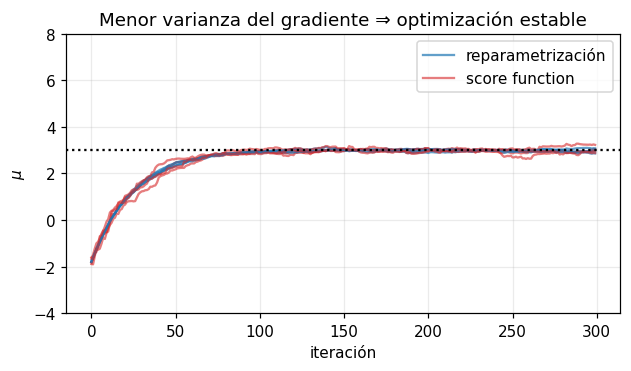

In [19]:
# ---- Efecto de la varianza al optimizar: ajustar mu de q=N(mu,1) para minimizar E_q[(z-3)^2] ----
def run(estimator, steps=300, lr=0.02, batch=8, seed=0):
    tf.random.set_seed(seed); mu = tf.Variable(-2.0); s = 1.0; tr = []
    for _ in range(steps):
        e = tf.random.normal((batch,)); zz = mu + s*e
        if estimator == "rep":  g = tf.reduce_mean(2*(zz-3.0))
        else:                   g = tf.reduce_mean((zz-3.0)**2 * (zz-mu)/s**2)
        mu.assign_sub(lr*g); tr.append(mu.numpy())
    return np.array(tr)

plt.figure(figsize=(6.5,3.3))
for seed in range(4):
    plt.plot(run("rep", seed=seed), "tab:blue", alpha=.7, label="reparametrización" if seed==0 else None)
    plt.plot(run("sf",  seed=seed), "tab:red",  alpha=.6, label="score function" if seed==0 else None)
plt.axhline(3, color="k", ls=":"); plt.ylim(-4, 8); plt.xlabel("iteración"); plt.ylabel(r"$\mu$")
plt.title("Menor varianza del gradiente ⇒ optimización estable"); plt.legend(); plt.show()


## **II.5. Implementación de un VAE en TensorFlow**

Construimos un **autoencoder variacional (VAE)** integrando los **Teoremas 3, 4 y 5** mediante cuatro etapas:

1. **Codificador probabilístico:** transforma la entrada $\boldsymbol{x}$ en los parámetros de la distribución latente:

   $$
   \boldsymbol{x}\longmapsto
   \left(\boldsymbol{\mu}_\phi(\boldsymbol{x}),
   \log\boldsymbol{\sigma}_\phi^2(\boldsymbol{x})\right).
   $$

   Se predice el **logaritmo de la varianza** para mejorar la estabilidad numérica y obtener varianzas positivas mediante la función exponencial, sin restringir la salida de la red.

2. **Muestreo reparametrizado (Teorema 5):** permite generar variables latentes manteniendo la diferenciabilidad:

   $$
   \boxed{
   \boldsymbol{z}=\boldsymbol{\mu}_\phi(\boldsymbol{x})
   +\exp\left(\frac12\log\boldsymbol{\sigma}_\phi^2(\boldsymbol{x})\right)
   \odot\boldsymbol{\varepsilon},
   \quad \boldsymbol{\varepsilon}\sim\mathcal{N}(0,I)
   }
   $$

3. **Decodificador probabilístico:** transforma $\boldsymbol{z}$ en los **logits** de una distribución Bernoulli. Al aplicar la función sigmoide se obtienen las probabilidades de reconstrucción:

   $$
   \boldsymbol{z}\xrightarrow{f_\theta}\boldsymbol{a}
   \xrightarrow{\operatorname{sigmoid}}\hat{\boldsymbol{x}}.
   $$

4. **Función de pérdida (Teoremas 3 y 4):** minimiza el **negativo de la ELBO**, combinando reconstrucción y regularización:

   $$
   \boxed{
   \mathcal{J}_{VAE}=
   \underbrace{\mathcal{J}_{rec}}_{\text{Entropía cruzada}}
   +\underbrace{\mathcal{J}_{KL}}_{\text{Regularización gaussiana}}
   }
   $$

   La **reconstrucción se suma sobre las características** y la **KL se calcula analíticamente**; posteriormente, ambas se promedian sobre el lote.

**Objetivo:** implementar un modelo que aprenda simultáneamente a **reconstruir observaciones**, **regularizar el espacio latente** y **generar nuevos datos** mediante muestreo probabilístico.


### **Experimento 7 · VAE convolucional sobre MNIST**

Se prepara la colección de dígitos manuscritos para estudiar reconstrucción probabilística, espacio latente y generación. Los gráficos se muestran en las celdas posteriores.

In [20]:
# ---- MNIST (decodificador Bernoulli con intensidades en [0,1]) ----
(xm_tr, ym_tr), (xm_te, ym_te) = keras.datasets.mnist.load_data()
xm_tr = (xm_tr.astype("float32")/255.)[..., None]
xm_te = (xm_te.astype("float32")/255.)[..., None]
print(xm_tr.shape, xm_te.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


In [21]:
# VAE: muestreo diferenciable; la función de pérdida se calcula en train_step.
class Sampling(layers.Layer):
    # Truco de reparametrización (Teorema 5): z = mu + sigma * eps
    def call(self, inputs):
        mu, logvar = inputs
        eps = tf.random.normal(tf.shape(mu))
        return mu + tf.exp(0.5*logvar) * eps

def build_encoder(latent_dim):
    inp = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)
    h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Flatten()(h)
    h = layers.Dense(128, activation="relu")(h)
    mu     = layers.Dense(latent_dim, name="mu")(h)
    logvar = layers.Dense(latent_dim, name="logvar")(h)
    z = Sampling(name="z")([mu, logvar])
    return keras.Model(inp, [mu, logvar, z], name="encoder")

def build_decoder(latent_dim):
    inp = keras.Input(shape=(latent_dim,))
    h = layers.Dense(128, activation="relu")(inp)
    h = layers.Dense(7*7*64, activation="relu")(h)
    h = layers.Reshape((7, 7, 64))(h)
    h = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)
    logits = layers.Conv2D(1, 3, padding="same", name="logits")(h)       # logits Bernoulli (más estable)
    return keras.Model(inp, logits, name="decoder")

class VAE(keras.Model):
    def __init__(self, latent_dim, beta=1.0, **kw):
        super().__init__(**kw)
        self.latent_dim = latent_dim
        self.beta = tf.Variable(beta, trainable=False, dtype=tf.float32)
        self.encoder = build_encoder(latent_dim)
        self.decoder = build_decoder(latent_dim)
        self.total_t = keras.metrics.Mean(name="loss")
        self.rec_t   = keras.metrics.Mean(name="recon")
        self.kl_t    = keras.metrics.Mean(name="kl")

    @property
    def metrics(self): return [self.total_t, self.rec_t, self.kl_t]

    def compute_losses(self, x):
        mu, logvar, z = self.encoder(x)
        logits = self.decoder(z)
        # -log p(x|z) para Bernoulli: SUMA sobre píxeles, media sobre el lote
        rec = tf.reduce_mean(tf.reduce_sum(
            tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=logits), axis=[1, 2, 3]))
        # KL cerrada (Teorema 4): suma sobre dimensiones latentes
        kl = tf.reduce_mean(0.5*tf.reduce_sum(tf.square(mu) + tf.exp(logvar) - 1. - logvar, axis=1))
        return rec, kl

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            rec, kl = self.compute_losses(x)
            loss = rec + self.beta*kl                         # beta=1  =>  -ELBO
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_t.update_state(loss); self.rec_t.update_state(rec); self.kl_t.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        rec, kl = self.compute_losses(x)
        self.total_t.update_state(rec + self.beta*kl); self.rec_t.update_state(rec); self.kl_t.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def call(self, x):                                       # reconstrucción determinista (usa mu)
        mu, _, _ = self.encoder(x)
        return tf.sigmoid(self.decoder(mu))

# Empezamos con 2-D para poder visualizar el espacio latente
vae2 = VAE(2)
vae2.compile(optimizer=keras.optimizers.Adam(1e-3))
h2 = vae2.fit(xm_tr, epochs=15, batch_size=128, verbose=2)

Epoch 1/15
469/469 - 11s - 24ms/step - kl: 3.4063 - loss: 195.5963 - recon: 192.1899
Epoch 2/15
469/469 - 10s - 21ms/step - kl: 5.0528 - loss: 163.5472 - recon: 158.4944
Epoch 3/15
469/469 - 10s - 21ms/step - kl: 5.5059 - loss: 157.8548 - recon: 152.3489
Epoch 4/15
469/469 - 11s - 24ms/step - kl: 5.7269 - loss: 154.8593 - recon: 149.1323
Epoch 5/15
469/469 - 11s - 24ms/step - kl: 5.9019 - loss: 152.8174 - recon: 146.9156
Epoch 6/15
469/469 - 11s - 24ms/step - kl: 6.0157 - loss: 151.4921 - recon: 145.4764
Epoch 7/15
469/469 - 11s - 24ms/step - kl: 6.1047 - loss: 150.3680 - recon: 144.2633
Epoch 8/15
469/469 - 11s - 23ms/step - kl: 6.1714 - loss: 149.4783 - recon: 143.3069
Epoch 9/15
469/469 - 11s - 24ms/step - kl: 6.2360 - loss: 148.8110 - recon: 142.5750
Epoch 10/15
469/469 - 11s - 24ms/step - kl: 6.2905 - loss: 148.2181 - recon: 141.9275
Epoch 11/15
469/469 - 12s - 25ms/step - kl: 6.3446 - loss: 147.6263 - recon: 141.2819
Epoch 12/15
469/469 - 11s - 24ms/step - kl: 6.3721 - loss: 147.

### **Diagnóstico gráfico del entrenamiento del VAE**

Se comparan la **pérdida total**, el componente de **reconstrucción** y el término de **regularización KL**. Las escalas de cada curva deben interpretarse con su definición.

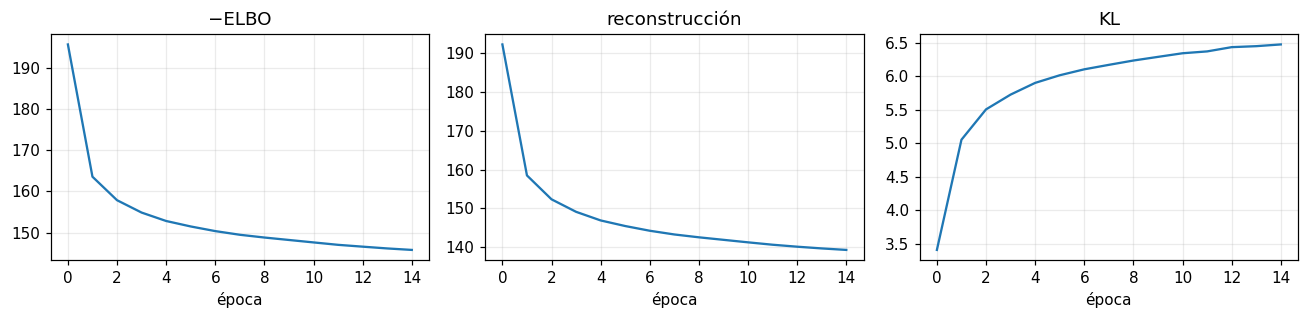

In [22]:
# ---- Curvas de entrenamiento: reconstrucción vs KL ----
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, k, t in zip(ax, ["loss", "recon", "kl"], ["−ELBO", "reconstrucción", "KL"]):
    a.plot(h2.history[k]); a.set_title(t); a.set_xlabel("época")
plt.tight_layout(); plt.show()

### **Visualización del espacio latente variacional**

Las medias latentes se proyectan en dos dimensiones y se colorean por la etiqueta verdadera. **Qué observar:** continuidad, agrupaciones y posibles superposiciones.

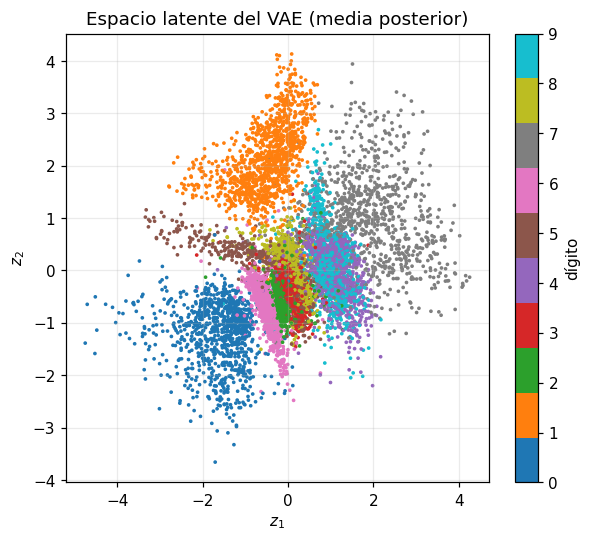

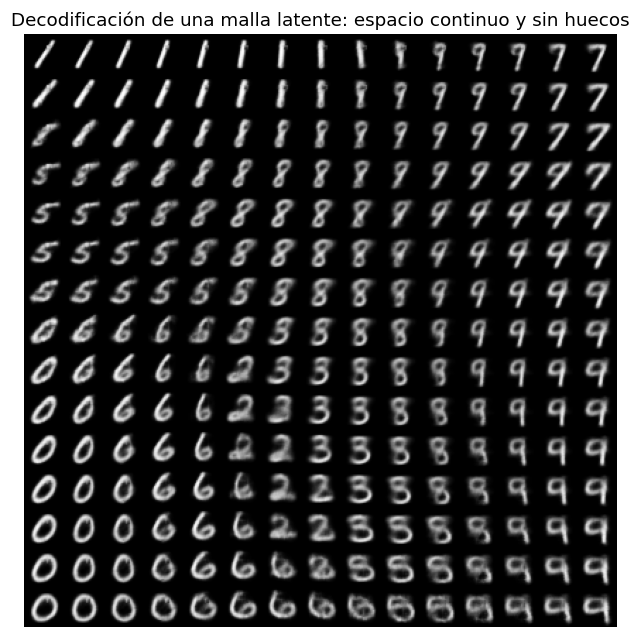

In [23]:
# ---- (1) Espacio latente 2-D coloreado por dígito ----
mu_te, lv_te, _ = vae2.encoder.predict(xm_te, batch_size=1024, verbose=0)
plt.figure(figsize=(6.2, 5.3))
sc = plt.scatter(mu_te[:,0], mu_te[:,1], c=ym_te, cmap="tab10", s=2)
plt.colorbar(sc, label="dígito"); plt.title("Espacio latente del VAE (media posterior)")
plt.xlabel("$z_1$"); plt.ylabel("$z_2$"); plt.show()

# ---- (2) Variedad generada: decodificar una malla del espacio latente ----
from scipy.stats import norm
n = 15
grid_x = norm.ppf(np.linspace(0.05, 0.95, n))
canvas = np.zeros((28*n, 28*n))
for i, yi in enumerate(grid_x[::-1]):
    for j, xi in enumerate(grid_x):
        img = tf.sigmoid(vae2.decoder(np.array([[xi, yi]], dtype="float32"))).numpy().reshape(28, 28)
        canvas[i*28:(i+1)*28, j*28:(j+1)*28] = img
plt.figure(figsize=(7, 7)); plt.imshow(canvas, cmap="gray"); plt.axis("off")
plt.title("Decodificación de una malla latente: espacio continuo y sin huecos"); plt.show()

### **Generación de nuevas imágenes**

Se muestrean códigos \(z\) del prior normal y se decodifican. **Qué observar:** diversidad y plausibilidad visual de las imágenes generadas.

Epoch 1/15
469/469 - 13s - 27ms/step - kl: 8.9408 - loss: 175.9720 - recon: 167.0312
Epoch 2/15
469/469 - 11s - 24ms/step - kl: 18.2773 - loss: 118.0641 - recon: 99.7868
Epoch 3/15
469/469 - 11s - 24ms/step - kl: 19.6688 - loss: 110.2517 - recon: 90.5830
Epoch 4/15
469/469 - 11s - 24ms/step - kl: 20.5077 - loss: 106.7934 - recon: 86.2857
Epoch 5/15
469/469 - 11s - 23ms/step - kl: 20.9366 - loss: 104.7766 - recon: 83.8400
Epoch 6/15
469/469 - 11s - 23ms/step - kl: 21.2738 - loss: 103.3817 - recon: 82.1080
Epoch 7/15
469/469 - 11s - 24ms/step - kl: 21.5739 - loss: 102.3053 - recon: 80.7314
Epoch 8/15
469/469 - 11s - 24ms/step - kl: 21.7834 - loss: 101.5246 - recon: 79.7412
Epoch 9/15
469/469 - 11s - 24ms/step - kl: 21.9087 - loss: 100.8373 - recon: 78.9285
Epoch 10/15
469/469 - 11s - 24ms/step - kl: 22.0293 - loss: 100.3227 - recon: 78.2934
Epoch 11/15
469/469 - 11s - 24ms/step - kl: 22.0986 - loss: 99.8436 - recon: 77.7451
Epoch 12/15
469/469 - 11s - 24ms/step - kl: 22.1638 - loss: 99.4

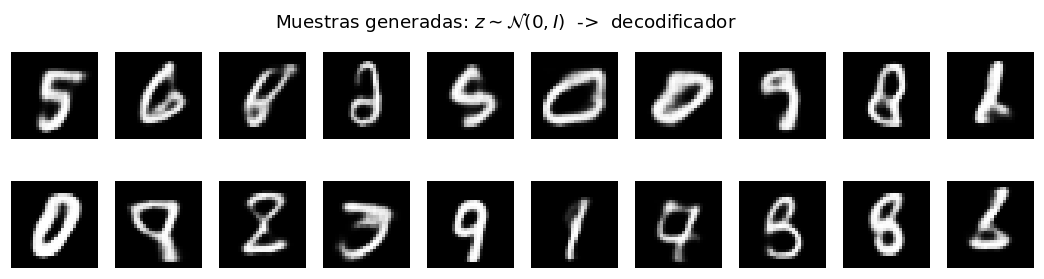

In [24]:
# ---- (3) Muestreo generativo z ~ N(0, I) con un VAE de 16 dimensiones ----
vae16 = VAE(16)
vae16.compile(optimizer=keras.optimizers.Adam(1e-3))
h16 = vae16.fit(xm_tr, epochs=15, batch_size=128, verbose=2)

z_prior = tf.random.normal((20, 16))
gen = tf.sigmoid(vae16.decoder(z_prior)).numpy().reshape(-1, 28, 28)
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for i in range(20): ax[i//10, i%10].imshow(gen[i], cmap="gray"); ax[i//10, i%10].axis("off")
fig.suptitle(r"Muestras generadas: $z\sim\mathcal{N}(0,I)$  ->  decodificador"); plt.show()

### **Interpolación en el espacio latente**

Se conectan dos códigos latentes mediante una trayectoria para observar transiciones entre reconstrucciones.

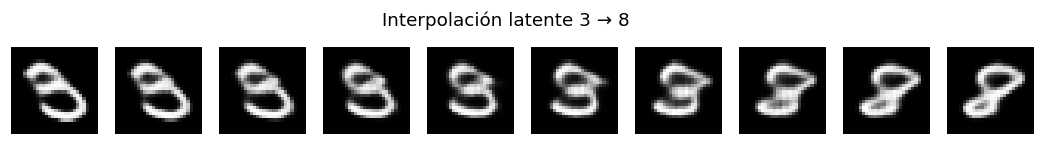

In [25]:
# ---- (4) Interpolación latente entre dos dígitos ----
def interpolate(model, xa, xb, steps=10):
    za = model.encoder(xa[None])[0]; zb = model.encoder(xb[None])[0]
    ts = np.linspace(0, 1, steps)[:, None].astype("float32")
    zs = (1-ts)*za.numpy() + ts*zb.numpy()
    return tf.sigmoid(model.decoder(zs)).numpy().reshape(-1, 28, 28)

ia, ib = np.where(ym_te == 3)[0][0], np.where(ym_te == 8)[0][0]
seq = interpolate(vae16, xm_te[ia], xm_te[ib])
fig, ax = plt.subplots(1, 10, figsize=(12, 1.5))
for i in range(10): ax[i].imshow(seq[i], cmap="gray"); ax[i].axis("off")
fig.suptitle("Interpolación latente 3 → 8"); plt.show()


## **II.6 Cotas más ajustadas: Importance Weighted Autoencoders**

El ELBO del Teorema 3 puede ser una cota poco ajustada. **IWAE** (Burda et al., 2016) utiliza $K$ muestras $z_1,\ldots,z_K\overset{iid}{\sim}q_\phi(z\mid x)$ y **pesos de importancia positivos** $w_k=p_\theta(x,z_k)/q_\phi(z_k\mid x)$:

$$\boxed{\mathcal L_K(x)=\mathbb E\left[\log\left(\frac1K\sum_{k=1}^K w_k\right)\right]},\qquad \mathcal L_1=\mathrm{ELBO}.$$

### **Teorema 6 · Monotonía de la cota IWAE**

**¿Qué queremos demostrar?** Que usar más muestras **no empeora la cota en esperanza**: $\mathcal L_1\le\mathcal L_2\le\cdots\le\log p_\theta(x)$. Además, bajo condiciones adicionales de integrabilidad, $\mathcal L_K\to\log p_\theta(x)$.

**Hipótesis:** $q$ debe cubrir el soporte relevante de $p_\theta(x,z)$, los $w_k$ son estrictamente positivos casi seguramente y las esperanzas de logaritmos existen. Para una prueba simple de convergencia basta suponer $0<a\le w_k\le b<\infty$; la monotonía no requiere esta acotación tan fuerte.

**Referencias guía:** Burda, Grosse y Salakhutdinov (2016, [26]); Cremer et al. (2017, [27]).


#### **· Teorema 6 (IWAE)**

**Objetivo.** Demostrar la cota, su monotonía en el número de muestras y el sentido preciso de su convergencia.

**Paso 1. Calcular la esperanza de los pesos.** Por la definición de importancia, suponiendo soporte adecuado,

$$\mathbb E_q[w_k]=\int q(z\mid x)\frac{p_\theta(x,z)}{q(z\mid x)}\,dz
=\int p_\theta(x,z)\,dz=p_\theta(x).$$

Por linealidad, el estimador $\widehat p_K=K^{-1}\sum_{k=1}^K w_k$ es **insesgado**: $\mathbb E[\widehat p_K]=p_\theta(x)$.

**Paso 2. Demostrar la cota superior.** La función $\log$ es cóncava; por Jensen,

$$\boxed{\mathcal L_K=\mathbb E[\log\widehat p_K]
\le\log\mathbb E[\widehat p_K]=\log p_\theta(x)}.$$

**Paso 3. Comparar $K+1$ muestras con $K$.** Dados $w_1,\ldots,w_{K+1}$, excluyamos al azar uno de los $K+1$ índices. Si $I$ es el conjunto aleatorio de los otros $K$ índices,

$$\mathbb E_I\left[\frac1K\sum_{i\in I}w_i\right]
=\frac1{K+1}\sum_{i=1}^{K+1}w_i,$$

porque cada $w_i$ aparece en $K$ de los $K+1$ subconjuntos y aporta $K/(K+1)$ veces su valor al numerador antes de dividir por $K$.

**Paso 4. Aplicar Jensen condicional.** Manteniendo fijos los pesos,

$$\log\left(\frac1{K+1}\sum_{k=1}^{K+1}w_k\right)
=\log\mathbb E_I\left[\frac1K\sum_{i\in I}w_i\right]
\ge\mathbb E_I\left[\log\left(\frac1K\sum_{i\in I}w_i\right)\right].$$

Tomando esperanza respecto de $w_1,\ldots,w_{K+1}$, cada subconjunto de $K$ pesos tiene la misma ley que una muestra iid de tamaño $K$. En consecuencia,

$$\boxed{\mathcal L_{K+1}\ge\mathcal L_K}.$$

**Paso 5. Probar convergencia (con hipótesis suficientes).** Como $\mathbb E[w_k]=p_\theta(x)$, por la ley fuerte de los grandes números,

$$\widehat p_K\xrightarrow{\mathrm{c.s.}}p_\theta(x)
\quad\Longrightarrow\quad
\log\widehat p_K\xrightarrow{\mathrm{c.s.}}\log p_\theta(x).$$

La convergencia casi segura **no basta por sí sola** para intercambiar logaritmo y esperanza. Si $0<a\le w_k\le b$, también $a\le\widehat p_K\le b$; entonces $|\log\widehat p_K|$ está dominado por una constante integrable, y el teorema de convergencia dominada asegura

$$\boxed{\lim_{K\to\infty}\mathcal L_K=\log p_\theta(x)}.\qquad\blacksquare$$

**Interpretación:** aumentar $K$ estrecha la cota **en esperanza**, pero no garantiza que cada estimación Monte Carlo individual aumente. Con pesos extremadamente variables puede requerirse un $K$ grande. Tampoco garantiza mejorar el entrenamiento del codificador, como advierten Rainforth et al. (2018, [29]).


### **Verificación numérica · Cota IWAE**

Se estima la cota con distintos tamaños de muestra y se contrasta su comportamiento con la evidencia del ejemplo conjugado.

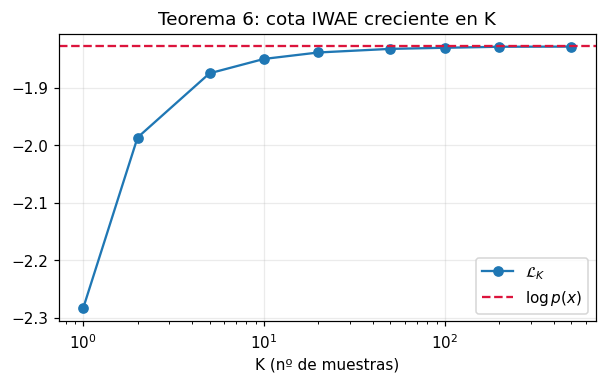

{1: np.float64(-2.2839), 2: np.float64(-1.9866), 5: np.float64(-1.8749), 10: np.float64(-1.8499), 20: np.float64(-1.8386), 50: np.float64(-1.8324), 100: np.float64(-1.8305), 200: np.float64(-1.8287), 500: np.float64(-1.8284)} | log p(x) = -1.828


: 

In [ ]:
# ---- Verificación del Teorema 6: L_K crece monótonamente hacia log p(x) (modelo conjugado) ----
rng = np.random.default_rng(0)
x0, qm, qs = 1.5, 0.2, 1.0
log_px = -0.5*(np.log(2*np.pi*2) + x0**2/2)

def L_K(K, R=60000):
    z = qm + qs*rng.normal(size=(R, K))
    logw = (-0.5*(np.log(2*np.pi)+z**2)) + (-0.5*(np.log(2*np.pi)+(x0-z)**2)) \
           - (-0.5*(np.log(2*np.pi*qs**2) + ((z-qm)/qs)**2))
    mx = logw.max(1, keepdims=True)
    return np.mean(mx[:, 0] + np.log(np.mean(np.exp(logw-mx), axis=1)))

Ks = [1, 2, 5, 10, 20, 50, 100, 200, 500]
vals = [L_K(K) for K in Ks]
plt.figure(figsize=(6.3, 3.4))
plt.semilogx(Ks, vals, "o-", label=r"$\mathcal{L}_K$")
plt.axhline(log_px, color="crimson", ls="--", label=r"$\log p(x)$")
plt.xlabel("K (nº de muestras)"); plt.title("Teorema 6: cota IWAE creciente en K"); plt.legend(); plt.show()
print({K: round(v, 4) for K, v in zip(Ks, vals)}, "| log p(x) =", round(log_px, 4))

In [ ]:
# ---- Estimar L_K en el VAE entrenado (MNIST, decodificador Bernoulli) ----
def iwae_bound(model, x, K=50):
    B = tf.shape(x)[0]
    mu, logvar, _ = model.encoder(x)
    mu, logvar = mu[:, None, :], logvar[:, None, :]                       # (B,1,m)
    eps = tf.random.normal((B, K, model.latent_dim))
    z = mu + tf.exp(0.5*logvar)*eps                                       # (B,K,m)
    logits = model.decoder(tf.reshape(z, (-1, model.latent_dim)))
    logits = tf.reshape(logits, (B, K, 28, 28, 1))
    xr = tf.repeat(x[:, None], K, axis=1)
    log_px_z = -tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=xr, logits=logits), axis=[2, 3, 4])
    log_pz   = tf.reduce_sum(-0.5*(z**2 + np.log(2*np.pi)), axis=2)
    log_qz   = tf.reduce_sum(-0.5*(eps**2 + np.log(2*np.pi) + logvar), axis=2)
    logw = log_px_z + log_pz - log_qz                                     # (B,K)
    return tf.reduce_mean(tf.reduce_logsumexp(logw, axis=1) - np.log(K))

xb = tf.constant(xm_te[:500])
for K in [1, 5, 50, 500]:
    print(f"K={K:4d}   L_K = {iwae_bound(vae16, xb, K).numpy():8.3f} nats")

K=   1   L_K =  -96.021 nats
K=   5   L_K =  -93.513 nats
K=  50   L_K =  -91.745 nats



## **II.7 Tasa–distorsión y $\beta$-VAE**

**Definiciones.** Sea $p_d(x)$ la distribución de datos, $q_\phi(z\mid x)$ el codificador, $p(z)$ el prior y $p_\theta(x\mid z)$ el decodificador.

- **Distorsión:** $D=-\mathbb E_{p_d(x)q_\phi(z\mid x)}[\log p_\theta(x\mid z)]$; representa el costo esperado de reconstruir.
- **Tasa:** $R=\mathbb E_{p_d(x)}[D_{KL}(q_\phi(z\mid x)\|p(z))]$; cuantifica la desviación del código respecto al prior.
- **Posterior agregada:** $q_\phi(z)=\int p_d(x)q_\phi(z\mid x)\,dx$.

### **Teorema 7 · Descomposición tasa distorsión**

**¿Qué queremos demostrar?** Que la tasa controla la información que $z$ conserva sobre $x$ y que la pérdida negativa del VAE es exactamente $D+R$:

$$\boxed{R=I_q(X;Z)+D_{KL}(q_\phi(z)\|p(z))\ge I_q(X;Z)},$$

$$\boxed{H(X)-D\le I_q(X;Z)\le R},\qquad
\boxed{-\mathbb E_{p_d}\mathrm{ELBO}=D+R}.$$

**Hipótesis:** entropías y KL finitas, con densidades o probabilidades definidas sobre medidas compatibles. Para variables continuas, $H(X)$ es **entropía diferencial**, que puede ser negativa; las identidades siguen siendo válidas cuando los términos están bien definidos.

**Interpretación del $\beta$-VAE:** optimizar $D+\beta R$ ($\beta>0$) modifica el compromiso entre reconstrucción y compresión. **No se garantiza** que cualquier elección de $\beta$ recorra toda la frontera global: la parametrización neuronal, los mínimos locales y las regiones no convexas pueden limitarla.

**Referencias guía:** Alemi et al. (2018, [30]); Higgins et al. (2017, [31]); Hoffman y Johnson (2016, [32]).


#### **Demostración detallada · Teorema 7 (tasa–distorsión)**

**Objetivo.** Identificar la información mutua del código latente dentro del término de regularización del VAE y obtener las dos cotas que conectan representación y reconstrucción.

**Paso 1. Definir la distribución conjunta inducida.** Sea $q(x,z)=p_d(x)q_\phi(z\mid x)$ y su marginal $q_\phi(z)=\int q(x,z)\,dx$. Por definición,

$$I_q(X;Z)=\mathbb E_{q(x,z)}\left[\log\frac{q_\phi(z\mid x)}{q_\phi(z)}\right].$$

**Paso 2. Descomponer algebraicamente la tasa.** Introducimos $q_\phi(z)$ en el cociente:

$$\begin{aligned}
R&=\mathbb E_q\left[\log\frac{q_\phi(z\mid x)}{p(z)}\right]\\
&=\mathbb E_q\left[\log\frac{q_\phi(z\mid x)}{q_\phi(z)}\right]
+\mathbb E_q\left[\log\frac{q_\phi(z)}{p(z)}\right]\\
&=I_q(X;Z)+D_{KL}(q_\phi(z)\|p(z)).
\end{aligned}$$

**Paso 3. Obtener la cota superior de información.** Como $D_{KL}\ge0$,

$$\boxed{I_q(X;Z)\le R}.$$

**Paso 4. Obtener la cota inferior.** Bajo la distribución conjunta $q$, se cumple $I_q(X;Z)=H_{p_d}(X)-H_q(X\mid Z)$. Para cada valor de $z$, la divergencia entre el condicional verdadero inducido $q(x\mid z)$ y el decodificador $p_\theta(x\mid z)$ es no negativa:

$$D_{KL}(q(x\mid z)\|p_\theta(x\mid z))
=\mathbb E_{q(x\mid z)}[\log q(x\mid z)-\log p_\theta(x\mid z)]\ge0.$$

Integrando sobre $q(z)$ y reordenando,

$$\underbrace{-\mathbb E_{q(x,z)}\log p_\theta(x\mid z)}_{D}
\ge\underbrace{-\mathbb E_{q(x,z)}\log q(x\mid z)}_{H_q(X\mid Z)}.$$

Por tanto,

$$\boxed{I_q(X;Z)=H_{p_d}(X)-H_q(X\mid Z)\ge H_{p_d}(X)-D}.$$

**Paso 5. Recuperar la pérdida del VAE.** Del Teorema 3,

$$\mathrm{ELBO}(x)=\mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]-D_{KL}(q_\phi(z\mid x)\|p(z)).$$

Promediando sobre $p_d(x)$ y cambiando el signo,

$$\boxed{-\mathbb E_{p_d}\mathrm{ELBO}=D+R}.\qquad\blacksquare$$

**Paso 6. Interpretar el parámetro $\beta$.** El objetivo $D+\beta R$ es el lagrangiano (salvo la constante $-\beta C$) de $\min D$ sujeto a $R\le C$, con $\beta\ge0$. Un $\beta$ grande penaliza más la información desviada del prior; sin embargo, para una familia neuronal concreta, el compromiso logrado depende del entrenamiento.

> **Lectura docente:** dos modelos pueden tener pérdidas $D+R$ semejantes y, aun así, representaciones latentes diferentes. Conviene visualizar **ambas magnitudes**, y no solo la pérdida global.


### **Experimento 8 · Barrido de β y tasa–distorsión**

Se entrenan configuraciones con distinta intensidad de regularización. **Qué observar:** compromiso entre distorsión de reconstrucción y tasa KL.

In [ ]:
# ---- Barrido de beta: curva tasa–distorsión empírica (Teorema 7) ----
betas = [0.1, 0.5, 1.0, 2.0, 4.0, 8.0]
results, models_beta = [], {}
for b in betas:
    tf.random.set_seed(0)
    m_ = VAE(8, beta=b); m_.compile(optimizer=keras.optimizers.Adam(1e-3))
    m_.fit(xm_tr, epochs=6, batch_size=128, verbose=0)
    D_, R_ = [], []
    for i in range(0, len(xm_te), 1000):
        d, r = m_.compute_losses(tf.constant(xm_te[i:i+1000])); D_.append(d.numpy()); R_.append(r.numpy())
    results.append((b, np.mean(D_), np.mean(R_))); models_beta[b] = m_      # (beta, D, R)
    print(f"beta={b:4.1f}   D (recon)={np.mean(D_):7.2f}   R (KL)={np.mean(R_):6.2f}   D+R={np.mean(D_)+np.mean(R_):7.2f}")

rd = np.array(results)
plt.figure(figsize=(6.3, 3.8))
plt.plot(rd[:, 2], rd[:, 1], "o-")
for b, d, r in rd: plt.annotate(rf"$\beta$={b:g}", (r, d), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel("Tasa R = KL (nats)"); plt.ylabel("Distorsión D (nats)")
plt.title("Frontera tasa–distorsión del VAE (Teorema 7)"); plt.show()

### **Comparación visual entre modelos β-VAE**

Se muestran imágenes generadas por distintas configuraciones para complementar la curva tasa–distorsión.

In [ ]:
# ---- Efecto cualitativo de beta (reutiliza los modelos entrenados arriba) ----
fig, ax = plt.subplots(2, 6, figsize=(12, 4.2))
z_fix = tf.random.normal((1, 8), seed=1)
for j, b in enumerate(betas):
    mm = models_beta[b]
    ax[0, j].imshow(mm(xm_te[:1]).numpy().reshape(28, 28), cmap="gray"); ax[0, j].set_title(rf"$\beta$={b:g}"); ax[0, j].axis("off")
    ax[1, j].imshow(tf.sigmoid(mm.decoder(z_fix)).numpy().reshape(28, 28), cmap="gray"); ax[1, j].axis("off")
fig.suptitle("Fila 1: reconstrucción | Fila 2: muestra del prior (mismo z)"); plt.show()


## **II.8. Diagnóstico: colapso posterior, dimensiones activas y VAE condicional**

### **Colapso posterior (*Posterior Collapse*)**

El **colapso posterior** ocurre cuando la distribución aproximada del codificador se vuelve prácticamente independiente de la entrada:

$$
\boxed{
q_\phi(\boldsymbol{z}\mid\boldsymbol{x})\approx p(\boldsymbol{z})
}
$$

En esta situación, el **decodificador ignora la información latente** $\boldsymbol{z}$ y aprende a modelar los datos sin utilizarla, fenómeno frecuente en modelos con **decodificadores autorregresivos muy expresivos**.

**Interpretación matemática.** Según la descomposición del término de regularización $R$ (Teorema 7):

$$
R=I_q(\boldsymbol{x};\boldsymbol{z})
+D_{KL}(q_\phi(\boldsymbol{z})\|p(\boldsymbol{z})).
$$

Como ambos términos son no negativos:

$$
\boxed{
R\to0\quad\Longrightarrow\quad
I_q(\boldsymbol{x};\boldsymbol{z})\to0
}
$$

**Conclusión:** cuando la información mutua tiende a cero, la representación latente **deja de aportar información sobre la entrada**, comprometiendo la utilidad del codificador.

### **Diagnóstico por dimensiones activas**

Una forma de evaluar cuánto utiliza el VAE su espacio latente consiste en analizar la **variabilidad de las medias** producidas por el codificador.

Una dimensión latente $j$ se considera **activa** cuando:

$$
\boxed{
\operatorname{Var}_{\boldsymbol{x}}
\left[\mu_j(\boldsymbol{x})\right]>\delta
}
$$

donde:
- **$\mu_j(\boldsymbol{x})$:** media de la dimensión latente $j$.
- **$\operatorname{Var}_{\boldsymbol{x}}$:** varianza calculada sobre las observaciones.
- **$\delta=0.01$:** umbral utilizado por Burda et al. [26].

**Interpretación:**
- **Dimensión activa:** su media cambia significativamente entre observaciones y puede aportar información discriminativa.
- **Dimensión inactiva:** su media permanece aproximadamente constante y puede indicar escaso aprovechamiento de esa coordenada latente.

**Idea central:** el seguimiento de la **divergencia KL**, la **información mutua** y el **número de dimensiones activas** permite diagnosticar si el VAE está utilizando adecuadamente su representación latente.




### **Diagnóstico · Dimensiones latentes activas**

Se examina la variabilidad de las medias latentes entre observaciones; dimensiones casi constantes pueden indicar escaso uso de la representación.

In [ ]:
# ---- Dimensiones latentes activas: Var_x[mu_j(x)] > 0.01 ----
def active_units(model, x, thr=0.01):
    mu, _, _ = model.encoder.predict(x, batch_size=1024, verbose=0)
    v = mu.var(axis=0); return v, int((v > thr).sum())

big = VAE(32); big.compile(optimizer=keras.optimizers.Adam(1e-3))
big.fit(xm_tr, epochs=10, batch_size=128, verbose=0)
v, n_act = active_units(big, xm_te)
plt.figure(figsize=(7, 2.8))
plt.bar(range(32), v); plt.axhline(0.01, color="crimson", ls="--", label="umbral 0.01")
plt.xlabel("dimensión latente"); plt.ylabel(r"Var$_x[\mu_j]$"); plt.legend()
plt.title(f"Unidades activas: {n_act}/32  (el VAE usa solo las dimensiones que necesita)"); plt.show()

In [ ]:
# ---- KL annealing: callback que sube beta de 0 a 1 ----
class KLAnneal(keras.callbacks.Callback):
    def __init__(self, warmup_epochs=5): super().__init__(); self.w = warmup_epochs
    def on_epoch_begin(self, epoch, logs=None):
        self.model.beta.assign(min(1.0, epoch/self.w))

va = VAE(16); va.compile(optimizer=keras.optimizers.Adam(1e-3))
ha = va.fit(xm_tr, epochs=10, batch_size=128, callbacks=[KLAnneal(5)], verbose=2)

### VAE condicional (CVAE)

Condicionamos en una etiqueta \(\boldsymbol{y}\) (p.ej. el dígito). El ELBO se mantiene, con todas las densidades condicionadas:

$$
\log p_\theta(\boldsymbol{x}|\boldsymbol{y})\ \ge\ \mathbb{E}_{q_\phi(\boldsymbol{z}|\boldsymbol{x},\boldsymbol{y})}\big[\log p_\theta(\boldsymbol{x}|\boldsymbol{z},\boldsymbol{y})\big]-D_{KL}\big(q_\phi(\boldsymbol{z}|\boldsymbol{x},\boldsymbol{y})\|p(\boldsymbol{z}|\boldsymbol{y})\big).
$$

(La demostración es idéntica al Teorema 3 con \(\boldsymbol{y}\) como variable de condicionamiento fija; Sohn et al., 2015 [38].) Permite **generación controlada**: elegir la clase y variar el estilo con \(\boldsymbol{z}\).

### **Experimento 9 · VAE condicional (CVAE)**

Se genera una cuadrícula por etiqueta: **cada fila** representa una clase y **cada columna** una muestra del espacio latente.

In [ ]:
# ---- CVAE: generar un dígito elegido ----
class CVAE(keras.Model):
    def __init__(self, latent_dim=8, n_cls=10):
        super().__init__()
        self.latent_dim, self.n_cls = latent_dim, n_cls
        xin = keras.Input((28, 28, 1)); yin = keras.Input((n_cls,))
        h = layers.Flatten()(xin); h = layers.Concatenate()([h, yin])
        h = layers.Dense(256, activation="relu")(h)
        mu = layers.Dense(latent_dim)(h); lv = layers.Dense(latent_dim)(h)
        self.enc = keras.Model([xin, yin], [mu, lv])
        zin = keras.Input((latent_dim,)); yin2 = keras.Input((n_cls,))
        h = layers.Concatenate()([zin, yin2]); h = layers.Dense(256, activation="relu")(h)
        out = layers.Dense(784)(h)
        self.dec = keras.Model([zin, yin2], out)
        self.tr = keras.metrics.Mean(name="loss")
    @property
    def metrics(self): return [self.tr]
    def train_step(self, data):
        (x, y), _ = data
        with tf.GradientTape() as tape:
            mu, lv = self.enc([x, y]); z = mu + tf.exp(0.5*lv)*tf.random.normal(tf.shape(mu))
            logits = tf.reshape(self.dec([z, y]), (-1, 28, 28, 1))
            rec = tf.reduce_mean(tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=logits), [1, 2, 3]))
            kl = tf.reduce_mean(0.5*tf.reduce_sum(mu**2 + tf.exp(lv) - 1. - lv, 1))
            loss = rec + kl
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_variables), self.trainable_variables))
        self.tr.update_state(loss); return {"loss": self.tr.result()}

y_oh = keras.utils.to_categorical(ym_tr, 10).astype("float32")
cvae = CVAE(); cvae.compile(optimizer=keras.optimizers.Adam(1e-3))
cvae.fit((xm_tr, y_oh), y_oh, epochs=12, batch_size=128, verbose=2)

fig, ax = plt.subplots(10, 8, figsize=(8, 10))
for d in range(10):
    z = tf.random.normal((8, cvae.latent_dim)); yy = tf.one_hot([d]*8, 10)
    im = tf.sigmoid(cvae.dec([z, yy])).numpy().reshape(8, 28, 28)
    for j in range(8): ax[d, j].imshow(im[j], cmap="gray"); ax[d, j].axis("off")
fig.suptitle("CVAE: cada fila = una clase; columnas = estilos (z)"); plt.show()

### **Aplicación: detección de anomalías con VAE**

La log-verosimilitud aproximada (ELBO o IWAE) sirve como **puntuación de anomalía**: entradas atípicas tendrán un ELBO bajo. *Advertencia:* los modelos profundos pueden asignar alta verosimilitud a datos fuera de distribución (Nalisnick et al., 2019 [39]); conviene contrastar con otras métricas.

### **Experimento 10 · Detección de anomalías**

Se comparan puntuaciones basadas en el ELBO de imágenes MNIST y Fashion-MNIST. **Qué observar:** solapamiento de distribuciones y AUROC, sin confundir una puntuación con una garantía de detección.

In [ ]:
# ---- Anomalías: entrenado con MNIST, se puntúa con ELBO a MNIST (in) vs Fashion-MNIST (out) ----
def elbo_score(model, x):
    out = []
    for i in range(0, len(x), 1000):
        xb = tf.constant(x[i:i+1000])
        mu, lv, z = model.encoder(xb)
        logits = model.decoder(z)
        rec = tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=xb, logits=logits), [1, 2, 3])
        kl = 0.5*tf.reduce_sum(mu**2 + tf.exp(lv) - 1. - lv, 1)
        out.append((-(rec + kl)).numpy())            # ELBO por muestra
    return np.concatenate(out)

s_in  = elbo_score(vae16, xm_te)
s_out = elbo_score(vae16, x_te[:len(xm_te)])         # Fashion-MNIST como anomalía
from sklearn.metrics import roc_auc_score
y_true = np.r_[np.zeros_like(s_in), np.ones_like(s_out)]
print("AUROC (ELBO como detector):", roc_auc_score(y_true, -np.r_[s_in, s_out]))
plt.figure(figsize=(6, 3)); plt.hist(s_in, 60, alpha=.6, label="MNIST (in)"); plt.hist(s_out, 60, alpha=.6, label="Fashion (out)")
plt.xlabel("ELBO"); plt.legend(); plt.title("Detección de anomalías"); plt.show()


## **Ejercicios propuestos**

**Teóricos**

1. **(Teorema 1)** Complete el Paso 3 mostrando que \(\boldsymbol{A}=\boldsymbol{W}_2\boldsymbol{W}_1\) es idempotente. ¿Qué falla si \(\Sigma\) tiene autovalores repetidos? (Pista: el subespacio invariante ya no es único.)
2. **(Teorema 2)** Demuestre la fórmula de Tweedie para ruido no isotrópico \(\mathcal{N}(0,\Sigma_\eta)\): \(r(\tilde{\boldsymbol{x}})=\tilde{\boldsymbol{x}}+\Sigma_\eta\nabla\log p_\eta(\tilde{\boldsymbol{x}})\).
3. **(Teorema 3)** Pruebe que si \(q_\phi(\boldsymbol{z}|\boldsymbol{x})\) pertenece a una familia que *contiene* a la posterior verdadera, el máximo del ELBO sobre \(\phi\) es \(\log p_\theta(\boldsymbol{x})\).
4. **(Teorema 4)** Derive la KL entre \(\mathcal{N}(\boldsymbol{\mu}_1,\Sigma_1)\) y \(\mathcal{N}(\boldsymbol{\mu}_2,\Sigma_2)\) con covarianza completa.
5. **(Teorema 5)** Encuentre la reparametrización para una distribución **Laplace** y una **log-normal**. ¿Y para una **Gamma**? (Ver [24].)
6. **(Teorema 6)** Pruebe que \(\mathcal{L}_K\) es el ELBO de un modelo extendido con \(K\) muestras y un \(q\) aumentado (Cremer et al. [27]).
7. **(Teorema 7)** Muestre un ejemplo de dos modelos con igual ELBO y tasas distintas.

**Computacionales (TensorFlow)**

8. Reemplace el decodificador Bernoulli por uno **gaussiano con varianza aprendida** \(\mathcal{N}(\mu_\theta(\boldsymbol{z}),\sigma_\theta^2(\boldsymbol{z}))\) y compare en Fashion-MNIST. ¿Qué ocurre con \(\sigma_\theta\)?
9. Implemente un **IWAE** completo (entrene con \(\mathcal{L}_{K=5}\)) y compare \(\mathcal{L}_{5000}\) en test con el VAE estándar.
10. Implemente el **\(\beta\)-VAE con capacidad controlada** (Burgess et al. [33]): pérdida \(D+\gamma|R-C|\) con \(C\) creciente.
11. Implemente **free bits** y compare las unidades activas con KL annealing.
12. Entrene un VAE sobre **datos tabulares financieros** (rendimientos de activos) y úselo para detectar días atípicos.



# **Referencias**

- **[1]** Baldi, P. & Hornik, K. (1989). *Neural networks and principal component analysis: Learning from examples without local minima*. **Neural Networks**, 2(1), 53–58. DOI: 10.1016/0893-6080(89)90014-2
- **[2]** Bourlard, H. & Kamp, Y. (1988). *Auto-association by multilayer perceptrons and singular value decomposition*. **Biological Cybernetics**, 59, 291–294.
- **[3]** Kunin, D., Bloom, J. M., Goeva, A. & Seed, C. (2019). *Loss landscapes of regularized linear autoencoders*. **ICML 2019**. arXiv:1901.08168.
- **[4]** Kramer, M. A. (1991). *Nonlinear principal component analysis using autoassociative neural networks*. **AIChE Journal**, 37(2), 233–243.
- **[5]** Eckart, C. & Young, G. (1936). *The approximation of one matrix by another of lower rank*. **Psychometrika**, 1, 211–218. / Jolliffe, I. T. (2002). *Principal Component Analysis*, 2nd ed. Springer.
- **[6]** Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning*. MIT Press. Cap. 14 (Autoencoders), Cap. 20 (Deep Generative Models). https://www.deeplearningbook.org
- **[7]** Vincent, P., Larochelle, H., Lajoie, I., Bengio, Y. & Manzagol, P.-A. (2010). *Stacked denoising autoencoders*. **JMLR**, 11, 3371–3408.
- **[8]** Ng, A. (2011). *Sparse autoencoder*. CS294A Lecture Notes, Stanford.
- **[9]** Rifai, S., Vincent, P., Muller, X., Glorot, X. & Bengio, Y. (2011). *Contractive auto-encoders: Explicit invariance during feature extraction*. **ICML 2011**.
- **[10]** Alain, G. & Bengio, Y. (2014). *What regularized auto-encoders learn from the data-generating distribution*. **JMLR**, 15, 3743–3773. arXiv:1211.4246.
- **[11]** Vincent, P. (2011). *A connection between score matching and denoising autoencoders*. **Neural Computation**, 23(7), 1661–1674.
- **[12]** Hyvärinen, A. (2005). *Estimation of non-normalized statistical models by score matching*. **JMLR**, 6, 695–709.
- **[13]** Efron, B. (2011). *Tweedie's formula and selection bias*. **JASA**, 106(496), 1602–1614.
- **[14]** Song, Y. & Ermon, S. (2019). *Generative modeling by estimating gradients of the data distribution*. **NeurIPS 2019**. arXiv:1907.05600.
- **[15]** Kingma, D. P. & Welling, M. (2014). *Auto-Encoding Variational Bayes*. **ICLR 2014**. arXiv:1312.6114.
- **[16]** Rezende, D. J., Mohamed, S. & Wierstra, D. (2014). *Stochastic backpropagation and approximate inference in deep generative models*. **ICML 2014**, PMLR 32. arXiv:1401.4082.
- **[17]** Blei, D. M., Kucukelbir, A. & McAuliffe, J. D. (2017). *Variational inference: A review for statisticians*. **JASA**, 112(518), 859–877. arXiv:1601.00670.
- **[18]** Jordan, M. I., Ghahramani, Z., Jaakkola, T. S. & Saul, L. K. (1999). *An introduction to variational methods for graphical models*. **Machine Learning**, 37, 183–233.
- **[19]** Kingma, D. P. & Welling, M. (2019). *An introduction to variational autoencoders*. **Foundations and Trends in Machine Learning**, 12(4), 307–392. arXiv:1906.02691. *(Lectura central recomendada)*
- **[20]** Cover, T. M. & Thomas, J. A. (2006). *Elements of Information Theory*, 2nd ed. Wiley.
- **[21]** Doersch, C. (2016). *Tutorial on variational autoencoders*. arXiv:1606.05908.
- **[22]** Mohamed, S., Rosca, M., Figurnov, M. & Mnih, A. (2020). *Monte Carlo gradient estimation in machine learning*. **JMLR**, 21(132), 1–62. arXiv:1906.10652.
- **[23]** Williams, R. J. (1992). *Simple statistical gradient-following algorithms for connectionist reinforcement learning*. **Machine Learning**, 8, 229–256.
- **[24]** Titsias, M. & Lázaro-Gredilla, M. (2014). *Doubly stochastic variational Bayes for non-conjugate inference*. **ICML 2014**.
- **[25]** Jang, E., Gu, S. & Poole, B. (2017). *Categorical reparameterization with Gumbel-Softmax*. **ICLR 2017**. arXiv:1611.01144. / Maddison, C., Mnih, A. & Teh, Y. W. (2017). *The Concrete distribution*. **ICLR 2017**.
- **[26]** Burda, Y., Grosse, R. & Salakhutdinov, R. (2016). *Importance weighted autoencoders*. **ICLR 2016**. arXiv:1509.00519.
- **[27]** Cremer, C., Morris, Q. & Duvenaud, D. (2017). *Reinterpreting importance-weighted autoencoders*. **ICLR 2017 Workshop**. arXiv:1704.02916.
- **[28]** Domke, J. & Sheldon, D. (2018). *Importance weighting and variational inference*. **NeurIPS 2018**. arXiv:1808.09034.
- **[29]** Rainforth, T., Kosiorek, A. R., Le, T. A., Maddison, C. J., Igl, M., Wood, F. & Teh, Y. W. (2018). *Tighter variational bounds are not necessarily better*. **ICML 2018**. arXiv:1802.04537.
- **[30]** Alemi, A. A., Poole, B., Fischer, I., Dillon, J. V., Saurous, R. A. & Murphy, K. (2018). *Fixing a broken ELBO*. **ICML 2018**, PMLR 80.
- **[31]** Higgins, I., Matthey, L., Pal, A., Burgess, C., Glorot, X., Botvinick, M., Mohamed, S. & Lerchner, A. (2017). *β-VAE: Learning basic visual concepts with a constrained variational framework*. **ICLR 2017**.
- **[32]** Hoffman, M. D. & Johnson, M. J. (2016). *ELBO surgery: yet another way to carve up the variational evidence lower bound*. **NIPS Workshop on Advances in Approximate Bayesian Inference**.
- **[33]** Burgess, C. P., Higgins, I., Pal, A., Matthey, L., Watters, N., Desjardins, G. & Lerchner, A. (2018). *Understanding disentangling in β-VAE*. arXiv:1804.03599.
- **[34]** Bowman, S. R., Vilnis, L., Vinyals, O., Dai, A., Jozefowicz, R. & Bengio, S. (2016). *Generating sentences from a continuous space*. **CoNLL 2016**. arXiv:1511.06349.
- **[35]** Kingma, D. P., Salimans, T., Jozefowicz, R., Chen, X., Sutskever, I. & Welling, M. (2016). *Improved variational inference with inverse autoregressive flow*. **NeurIPS 2016**. arXiv:1606.04934.
- **[36]** Lucas, J., Tucker, G., Grosse, R. & Norouzi, M. (2019). *Don't blame the ELBO! A linear VAE perspective on posterior collapse*. **NeurIPS 2019**. arXiv:1911.02469.
- **[37]** Dai, B. & Wipf, D. (2019). *Diagnosing and enhancing VAE models*. **ICLR 2019**. arXiv:1903.05789.
- **[38]** Sohn, K., Lee, H. & Yan, X. (2015). *Learning structured output representation using deep conditional generative models*. **NIPS 2015**.
- **[39]** Nalisnick, E., Matsukawa, A., Teh, Y. W., Gorur, D. & Lakshminarayanan, B. (2019). *Do deep generative models know what they don't know?* **ICLR 2019**. arXiv:1810.09136.
- Murphy, K. P. (2023). *Probabilistic Machine Learning: Advanced Topics*. MIT Press. (Cap. 21: VAEs.) https://probml.github.io/pml-book/book2.html
- Bishop, C. M. & Bishop, H. (2024). *Deep Learning: Foundations and Concepts*. Springer. (Caps. sobre variables latentes y VAEs.)
- Prince, S. J. D. (2023). *Understanding Deep Learning*. MIT Press. (Cap. 17: VAEs.) https://udlbook.github.io/udlbook/
- Chollet, F. (2021). *Deep Learning with Python*, 2nd ed. Manning. (Cap. 12: ejemplos VAE en Keras.)
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. (Cap. 10: Inferencia variacional.)